In [1]:
!pip install -q accelerate bitsandbytes

In [2]:
import os

# --- HIVE STORAGE REDIRECTION ---
# Define your path in the 20TB department storage
# Replace 'yourusername' with your actual Kerberos name
DEPT_STORAGE = "/group/gquongrp/workspaces/baran/AvalancheBreak"
os.makedirs(DEPT_STORAGE, exist_ok=True)

# Redirect Hugging Face cache to the department storage [cite: 59]
os.environ['HF_HOME'] = os.path.join(DEPT_STORAGE, "hf_cache")

# Update your results directory to also use the 20TB space [cite: 59]
output_dir = os.path.join(DEPT_STORAGE, "results")
os.makedirs(output_dir, exist_ok=True)
# --------------------------------

In [3]:
# ============================================================
# MODEL SELECTION
# ============================================================
# Change MODEL_ID (and re-run the notebook top to bottom) to repeat the
# exact same analysis at a different model scale -- e.g. to check whether
# the boundary-sink / entropy effects studied below hold up as the model
# gets bigger. Outputs are namespaced under results/<MODEL_TAG>/ so runs
# at different scales don't overwrite each other and can be compared
# side by side.

import os

MODEL_ID = "Qwen/Qwen2.5-7B-Instruct"
# MODEL_ID = "Qwen/Qwen2.5-14B-Instruct"  # ~28GB in bf16 -- fits alongside a 7B run on an 80GB A100

MODEL_TAG = MODEL_ID.split("/")[-1]
RESULTS_DIR = os.path.join("results", MODEL_TAG)
os.makedirs(RESULTS_DIR, exist_ok=True)

print(f"Model: {MODEL_ID}")
print(f"Results directory: {RESULTS_DIR}/")

Model: Qwen/Qwen2.5-7B-Instruct
Results directory: results/Qwen2.5-7B-Instruct/


In [4]:
import os
import shutil

# Set to True only if you explicitly want to wipe THIS model's prior
# results (including previously captured attention tensors) before a
# fresh run. Only clears results/<MODEL_TAG>/ -- results for other
# model scales (see the MODEL SELECTION cell above) are untouched.
CLEAR_PREVIOUS_RESULTS = False

if CLEAR_PREVIOUS_RESULTS:
    if os.path.isdir(RESULTS_DIR):
        shutil.rmtree(RESULTS_DIR)
        os.makedirs(RESULTS_DIR, exist_ok=True)
        print(f"Cleared '{RESULTS_DIR}/'")
else:
    print(f"Skipping cleanup (CLEAR_PREVIOUS_RESULTS=False) -- existing {RESULTS_DIR}/ is preserved.")

Skipping cleanup (CLEAR_PREVIOUS_RESULTS=False) -- existing results/Qwen2.5-7B-Instruct/ is preserved.


# Qwen Scaling

In [5]:
import pandas as pd
import numpy as np
import random
import itertools
import torch
from tqdm import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer

# --- 1. LOCAL MODEL SETUP ---
# MODEL_ID / MODEL_TAG / RESULTS_DIR come from the MODEL SELECTION cell above.
import os

print(f"Loading {MODEL_ID} into VRAM...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

# Full A100 headroom available: run in native bf16 rather than 8-bit.
# (int8 quantization noise is an unwanted confound for the attention/entropy
# analysis later in this notebook, and bnb int8 is often *slower* than bf16
# on A100 anyway.)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    device_map="auto",
    torch_dtype=torch.bfloat16,
    attn_implementation="eager",  # required: sdpa/flash-attn can't return attention weights,
                                   # and this notebook's Attention Analysis section needs them.
)
model.eval()

# --- 2. THE PARAMETER SPACE ---
ALPHABET_SIZES = [2, 4, 8]
SEQUENCE_LENGTHS = [4, 8, 16, 32, 64, 128, 256]
# Runtime note (measured on an A100): each generate() call costs roughly
# max_new_tokens / 34 seconds. At N=256 (~400 new tokens) that's ~12s/call;
# the full grid at this length list adds ~1.5h beyond the N<=32 baseline.
# Trim this list or TRIALS_T below for a faster pass.
PERIODIC_INTERVALS = [0, 2, 4, 8]   # 0 = Base
API_TEMPERATURES = [0.0]
TRIALS_T = 20

# Optional global seed for reproducibility of the whole experiment
GLOBAL_SEED = 42
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)
torch.manual_seed(GLOBAL_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(GLOBAL_SEED)

# --- 3. TASK ENGINE ---
class TaskEngine:
    def __init__(self, alphabet_size):
        self.alphabet_size = alphabet_size
        self.alphabet = [chr(ord('A') + i) for i in range(alphabet_size)]
        self.char_to_idx = {c: i for i, c in enumerate(self.alphabet)}

    def generate_raw_input(self, length, rng=None):
        if rng is None:
            rng = random
        return rng.choices(self.alphabet, k=length)

    def build_base_from_raw(self, raw_input):
        input_str = "".join(raw_input)
        output_str = "".join(
            self.alphabet[(self.char_to_idx[c] + 1) % self.alphabet_size]
            for c in raw_input
        )

        prompt = f"""You are a deterministic sequence transformer.
Task: Cyclic character shift.
Alphabet: {', '.join(self.alphabet)}
Rule: Replace every character with the next one in the alphabet.
Mapping: {self.alphabet[-1]} -> {self.alphabet[0]}, and {self.alphabet[0]} -> {self.alphabet[1]}.
Constraint: Output ONLY the transformed string.
No spaces, no explanations.

Input: {input_str}
Output: """
        return input_str, output_str, prompt

    def build_cellular_from_raw(self, raw_input, interval):
        input_w_bounds = ""
        output_w_bounds = ""

        for i, char in enumerate(raw_input):
            shifted_char = self.alphabet[(self.char_to_idx[char] + 1) % self.alphabet_size]
            input_w_bounds += char
            output_w_bounds += shifted_char

            if interval > 0 and (i + 1) % interval == 0 and i != len(raw_input) - 1:
                input_w_bounds += "|"
                output_w_bounds += "|"

        prompt = f"""You are a deterministic sequence transformer.
Task: Cyclic character shift.
Alphabet: {', '.join(self.alphabet)}
Rule: Replace every character with the next one in the alphabet.
Mapping: {self.alphabet[-1]} -> {self.alphabet[0]}, and {self.alphabet[0]} -> {self.alphabet[1]}.
Constraint: The input contains vertical bars (|). These are structural boundaries. DO NOT shift them. Copy them exactly to the output.
No spaces, no explanations.

Input: {input_w_bounds}
Output: """
        return input_w_bounds, output_w_bounds, prompt

# Cache TaskEngines
engines = {A: TaskEngine(A) for A in ALPHABET_SIZES}

# --- 4. PREGENERATE SHARED RAW SEQUENCES ---
# One shared raw sequence per (Alphabet_Size, Seq_Length, Trial)
shared_sequences = {}

for A in ALPHABET_SIZES:
    engine = engines[A]
    for N in SEQUENCE_LENGTHS:
        for t in range(TRIALS_T):
            # Independent deterministic seed per condition key
            local_seed = 10_000 * A + 100 * N + t
            rng = random.Random(local_seed)
            shared_sequences[(A, N, t)] = engine.generate_raw_input(N, rng=rng)

print(f"Pregenerated {len(shared_sequences)} shared raw sequences.")

# --- 5. WORKER FUNCTION FOR A SINGLE TRIAL ---
def run_single_trial(task_params):
    T_api, A, N, k, t = task_params
    engine = engines[A]
    method = "Base" if k == 0 else "Cellular_Bounds"

    # Use the SAME raw sequence for base and all cellular variants with same (A, N, t)
    raw_input = shared_sequences[(A, N, t)]

    if method == "Base":
        inp, truth, prompt = engine.build_base_from_raw(raw_input)
    else:
        inp, truth, prompt = engine.build_cellular_from_raw(raw_input, interval=k)

    # --- LOCAL INFERENCE ---
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    max_tokens_needed = int(N * 1.5) + 20

    do_sample = T_api > 0.0
    temp_val = T_api if do_sample else None

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_tokens_needed,
            temperature=temp_val,
            do_sample=do_sample,
            pad_token_id=tokenizer.eos_token_id
        )

    full_response = tokenizer.decode(outputs[0], skip_special_tokens=True)
    pred = full_response[len(prompt):].strip()

    pred = pred.split("Explanation")[0].split("\n")[0].strip()

    # --- CLEANING AND METRICS ---
    if method == "Cellular_Bounds":
        clean_pred = pred.replace("|", "").replace(" ", "").replace("\n", "")
        clean_truth = truth.replace("|", "")
    else:
        clean_pred = pred.replace(" ", "").replace("\n", "")
        clean_truth = truth

    clean_pred = clean_pred[:len(clean_truth)]

    binary_series = []
    for i in range(len(clean_truth)):
        if i < len(clean_pred) and clean_pred[i] == clean_truth[i]:
            binary_series.append(1)
        else:
            binary_series.append(0)

    tar = sum(binary_series) / len(clean_truth) if len(clean_truth) > 0 else 0.0
    sar = 1.0 if (
        len(binary_series) == len(clean_truth)
        and sum(binary_series) == len(binary_series)
    ) else 0.0
    first_error = binary_series.index(0) if 0 in binary_series else len(binary_series)

    return {
        "API_Temp": T_api,
        "Alphabet_Size": A,
        "Method": method,
        "Interval": k,
        "Seq_Length": N,
        "Trial": t,
        "Shared_Sequence": "".join(raw_input),   # useful for verification
        "TAR": tar,
        "SAR": sar,
        "First_Error_Pos": first_error,
        "Input_Given": inp,
        "Ground_Truth": clean_truth,
        "LLM_Output": clean_pred
    }

# --- 6. MAIN EXPERIMENT SETUP ---
tasks = list(itertools.product(
    API_TEMPERATURES,
    ALPHABET_SIZES,
    SEQUENCE_LENGTHS,
    PERIODIC_INTERVALS,
    range(TRIALS_T)
))

filtered_tasks = [task for task in tasks if task[3] == 0 or task[3] < task[2]]

total_calls = len(filtered_tasks)
print(f"\nStarting Grid Search with 7B Model: {total_calls} total evaluations.")

all_results = []

# --- 7. SEQUENTIAL EXECUTION ---
for task in tqdm(filtered_tasks, total=total_calls, desc="Generating"):
    try:
        result = run_single_trial(task)
        all_results.append(result)
    except Exception as exc:
        print(f"Task failed: {task} | Error: {exc}")

# --- 8. SAVE & SUMMARIZE ---
df = pd.DataFrame(all_results)

csv_filename = os.path.join(RESULTS_DIR, "thermodynamics_grid.csv")
df.to_csv(csv_filename, index=False)
print(f"\nExperiment complete. Saved to '{csv_filename}'")

summary = (
    df.groupby(["Alphabet_Size", "Seq_Length", "Method"])[["TAR", "SAR"]]
      .mean()
      .reset_index()
)

print("\n--- AVERAGE ACCURACY BY ALPHABET & LENGTH ---")
print(summary.to_string(index=False))

# --- 9. OPTIONAL VERIFICATION CHECK ---
# Confirms that for each (A, N, Trial), all intervals share the same raw sequence
verification = (
    df.groupby(["Alphabet_Size", "Seq_Length", "Trial"])["Shared_Sequence"]
      .nunique()
      .reset_index(name="Unique_Shared_Sequences")
)

print("\n--- SHARED SEQUENCE VERIFICATION ---")
print(verification["Unique_Shared_Sequences"].value_counts().sort_index())

if verification["Unique_Shared_Sequences"].max() == 1:
    print("Success: Base and Cellular conditions use the same raw sequence within each (A, N, Trial).")
else:
    print("Warning: Some trials do not share the same raw sequence across conditions.")

/group/gquongrp/workspaces/baran/AvalancheBreak/.conda/envs/qwen-focus/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading Qwen/Qwen2.5-7B-Instruct into VRAM...


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

Loading weights:   1%|          | 2/339 [00:00<00:18, 17.74it/s]

...

Generating: 100%|█████████▉| 1498/1500 [1:36:15<00:15,  7.85s/it]

Generating: 100%|█████████▉| 1499/1500 [1:36:22<00:07,  7.84s/it]

Generating: 100%|██████████| 1500/1500 [1:36:30<00:00,  7.91s/it]

Generating: 100%|██████████| 1500/1500 [1:36:30<00:00,  3.86s/it]


Experiment complete. Saved to 'results/Qwen2.5-7B-Instruct/thermodynamics_grid.csv'

--- AVERAGE ACCURACY BY ALPHABET & LENGTH ---
 Alphabet_Size  Seq_Length          Method      TAR      SAR
             2           4            Base 0.862500 0.600000
             2           4 Cellular_Bounds 0.912500 0.700000
             2           8            Base 0.725000 0.100000
             2           8 Cellular_Bounds 0.821875 0.525000
             2          16            Base 0.584375 0.000000
             2          16 Cellular_Bounds 0.708333 0.183333
             2          32            Base 0.537500 0.000000
             2          32 Cellular_Bounds 0.658854 0.133333
             2          64            Base 0.521875 0.000000
             2          64 Cellular_Bounds 0.622396 0.000000
             2         128            Base 0.523047 0.000000
             2         128 Cellular_Bounds 0.525651 0.000000
             2         256            Base 0.494531 0.000000
             2

## Qwen Visualuition of Scaling

      Seq_Length  Alphabet_Size  Interval       TAR  SAR
40             8              2         0  0.750000  0.0
41             8              2         0  0.375000  0.0
42             8              2         0  1.000000  1.0
43             8              2         0  0.875000  0.0
44             8              2         0  0.875000  0.0
...          ...            ...       ...       ...  ...
1495         256              8         8  0.152344  0.0
1496         256              8         8  0.179688  0.0
1497         256              8         8  0.101562  0.0
1498         256              8         8  0.128906  0.0
1499         256              8         8  0.058594  0.0

[1380 rows x 5 columns]


Saved plot to results/Qwen2.5-7B-Instruct/scaling_law_N8_plus.png


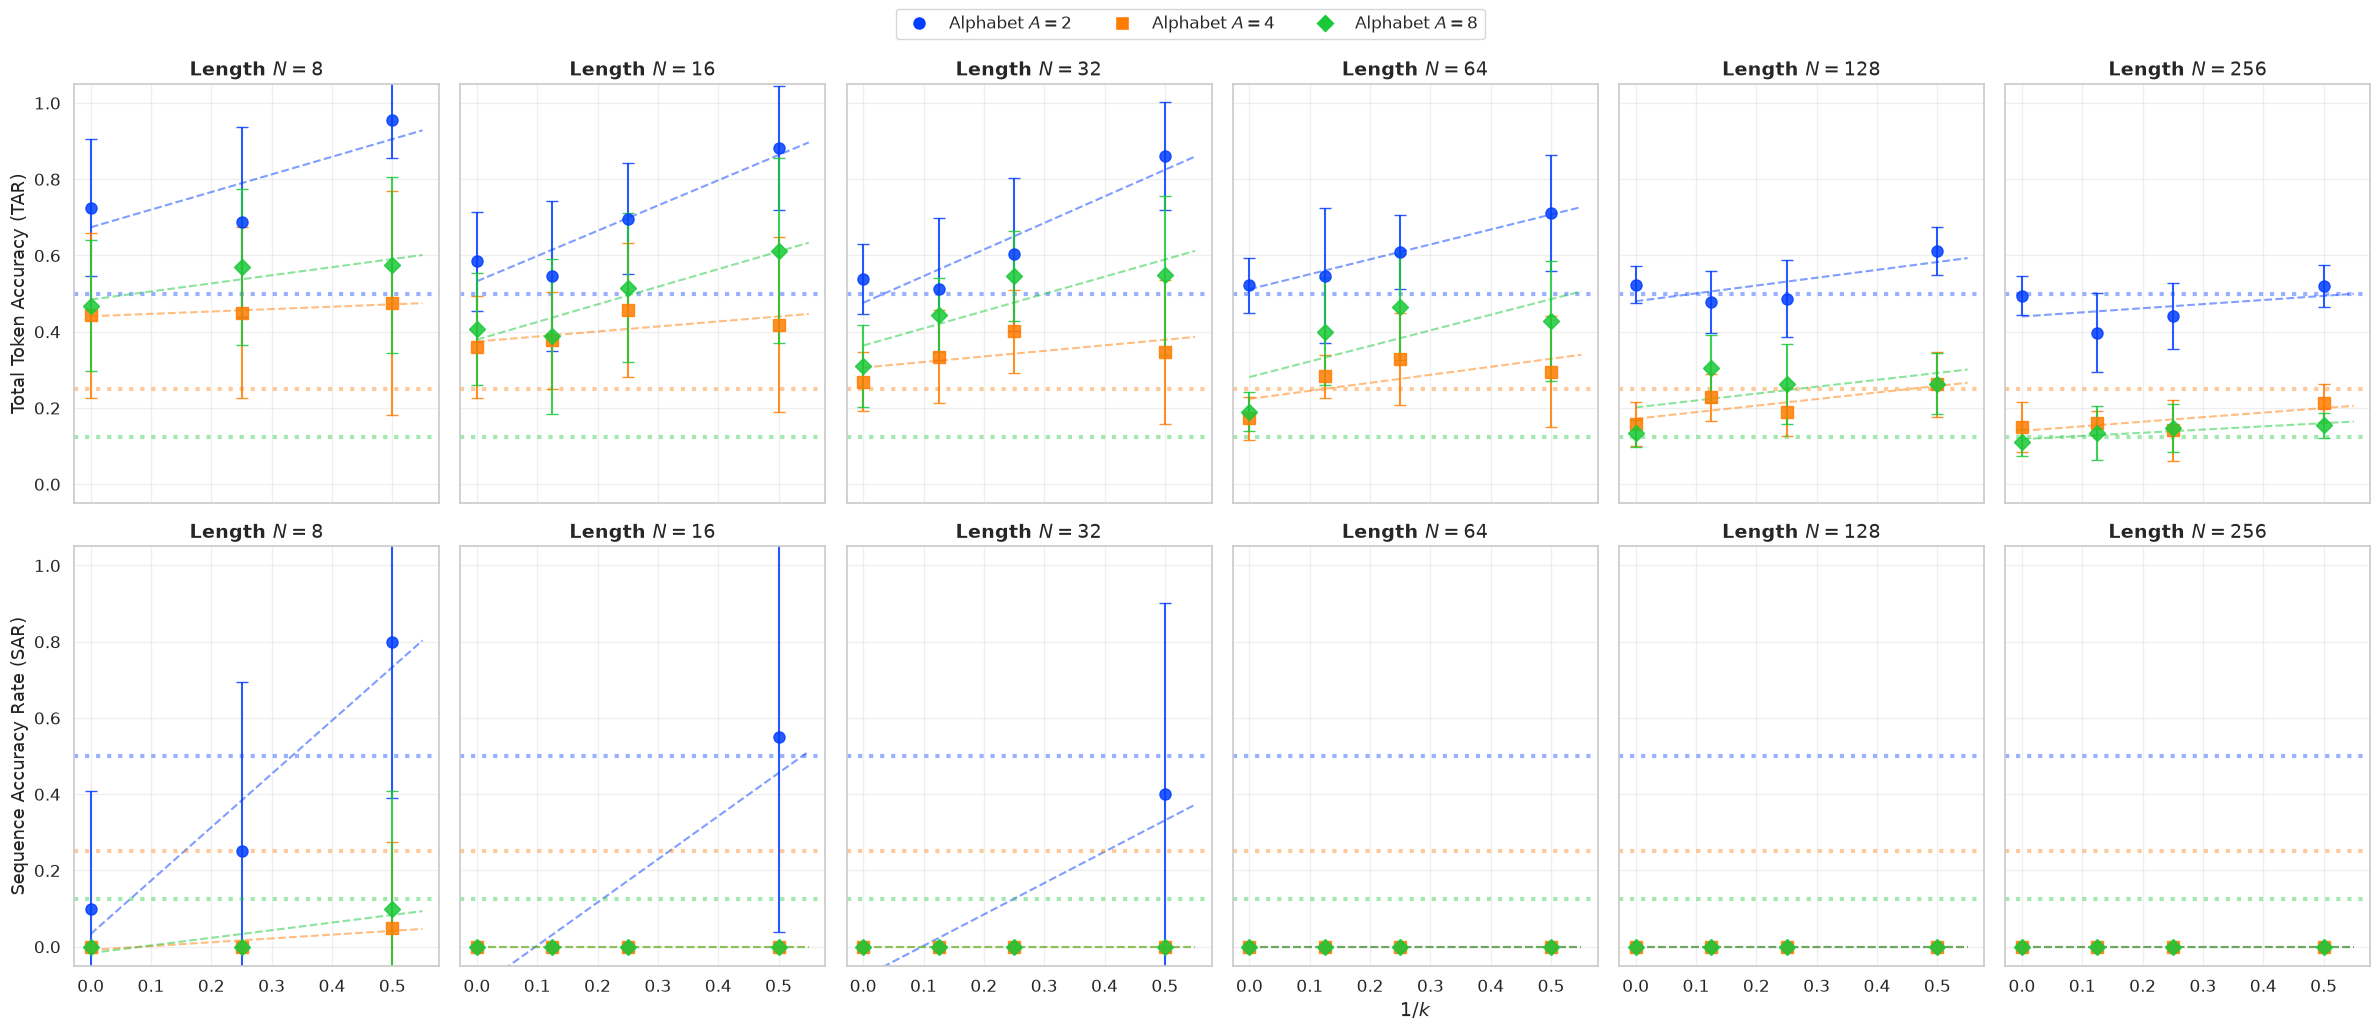


--- SCALING LAW REGRESSION (N >= 8), TAR and SAR ---

TAR:
Seq_Length    8      16     32     64     128    256
Alphabet                                            
2           0.631  0.886  0.871  0.986  0.514  0.177
4           0.893  0.421  0.327  0.441  0.667  0.638
8           0.794  0.890  0.737  0.501  0.269  0.819

SAR:
Seq_Length     8      16     32
Alphabet                       
2           0.902  0.771  0.771
4           0.750    NaN    NaN
8           0.750    NaN    NaN


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
import seaborn as sns
import os

# --- 1. LOAD DATA ---
file_path = os.path.join(RESULTS_DIR, "thermodynamics_grid.csv")
df = pd.read_csv(file_path)

# Robustly handle column names
if 'Accuracy' in df.columns and 'TAR' not in df.columns:
    df['TAR'] = df['Accuracy']
elif 'TAR' not in df.columns:
    raise ValueError("Dataset missing 'TAR' or 'Accuracy' column.")

# --- 2. CALCULATE 1/k (DEFECT DENSITY) WITH BASE CASE AT 0 ---

# Logic: If k=0 (Base), density is 0. If k>0, density is 1/k.
df['Inv_K'] = df['Interval'].apply(lambda k: 0.0 if k == 0 else 1.0/k)

# # --- FILTER: ONLY PLOT N >= 8 ---
df = df[df['Seq_Length'] >= 8]
#target_lengths = [128, 256, 512]
#df = df[df['Seq_Length'].isin(target_lengths)]

# Calculate mean AND std (across the 20 trials per condition) for both TAR and
# SAR -- SAR (whole-sequence exact match) is the paper's headline "accuracy
# cliff" metric, TAR (per-token accuracy) is the softer companion metric.
summary = (
    df.groupby(['Seq_Length', 'Alphabet_Size', 'Inv_K'])[['TAR', 'SAR']]
      .agg(['mean', 'std'])
)
summary.columns = ['_'.join(c) for c in summary.columns]
summary = summary.reset_index().sort_values(['Seq_Length', 'Alphabet_Size', 'Inv_K'])
summary[['TAR_std', 'SAR_std']] = summary[['TAR_std', 'SAR_std']].fillna(0.0)  # single-sample groups

print(df[['Seq_Length', 'Alphabet_Size', 'Interval', 'TAR', 'SAR']])

# --- 3. PLOTTING (TAR on top row, SAR on bottom row) ---
seq_lengths = sorted(summary['Seq_Length'].unique())
alphabet_sizes = sorted(summary['Alphabet_Size'].unique())
num_lengths = len(seq_lengths)

# Dynamic Styling
palette = sns.color_palette("bright", n_colors=len(alphabet_sizes))
colors = {A: col for A, col in zip(alphabet_sizes, palette)}
marker_list = ['o', 's', 'D', '^', 'v', '<', '>']
markers = {A: marker_list[i % len(marker_list)] for i, A in enumerate(alphabet_sizes)}

sns.set_theme(style="whitegrid", font_scale=1.1)

fig, axes = plt.subplots(2, max(num_lengths, 1), figsize=(4 * max(num_lengths, 1), 10),
                          sharex=True, sharey=True, squeeze=False)

regression_results = []

for row, (metric, ylabel) in enumerate([('TAR', 'Total Token Accuracy (TAR)'),
                                         ('SAR', 'Sequence Accuracy Rate (SAR)')]):
    for i, N in enumerate(seq_lengths):
        ax = axes[row][i]
        sub_N = summary[summary['Seq_Length'] == N]

        for A in alphabet_sizes:
            sub_A = sub_N[sub_N['Alphabet_Size'] == A]

            # Need at least 2 points for a line
            if len(sub_A) < 2: continue

            inv_k_vals = sub_A['Inv_K'].values
            metric_vals = sub_A[f'{metric}_mean'].values
            metric_err = sub_A[f'{metric}_std'].values

            # Linear Regression (Including the Base point at x=0)
            slope, intercept, r_value, p_value, std_err = linregress(inv_k_vals, metric_vals)

            regression_results.append({
                'Metric': metric,
                'Seq_Length': N,
                'Alphabet': A,
                'Slope': slope,
                'Intercept (Base Fit)': intercept,
                'R_squared': r_value**2
            })

            # --- PLOT DYNAMIC 1/A REFERENCE LINE (chance baseline) ---
            ax.axhline(1.0/A, color=colors[A], linestyle=':', alpha=0.4, linewidth=3)

            # Plot Data Points with error bars (std across the 20 trials)
            ax.errorbar(inv_k_vals, metric_vals, yerr=metric_err,
                        fmt=markers[A], color=colors[A], markersize=8, alpha=0.85,
                        capsize=4, linestyle='none')

            # Plot Fit Line
            x_fit = np.linspace(0, max(inv_k_vals) * 1.1, 100)
            y_fit = slope * x_fit + intercept
            ax.plot(x_fit, y_fit, linestyle='--', color=colors[A], alpha=0.5, linewidth=1.5)

        ax.set_title(f'Length $N = {N}$', fontsize=14, fontweight='bold')
        ax.set_ylim(-0.05, 1.05)
        ax.grid(True, alpha=0.3)

        if i == 0:
            ax.set_ylabel(ylabel, fontsize=13)
        if row == 1 and i == num_lengths // 2:
            ax.set_xlabel('$1/k$', fontsize=14)

# Legend
handles = [plt.Line2D([0], [0], marker=markers[A], color='w', markerfacecolor=colors[A],
                      markersize=10, label=f'Alphabet $A={A}$') for A in alphabet_sizes]
fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 1.04), ncol=len(alphabet_sizes), fontsize=12)

plt.tight_layout()
plot_path = os.path.join(RESULTS_DIR, 'scaling_law_N8_plus.png')
plt.savefig(plot_path, bbox_inches='tight', dpi=300)
print(f"Saved plot to {plot_path}")
plt.show()

# --- 4. PRINT RESULTS ---
print("\n--- SCALING LAW REGRESSION (N >= 8), TAR and SAR ---")
results_df = pd.DataFrame(regression_results).round(3)
for metric in ['TAR', 'SAR']:
    print(f"\n{metric}:")
    pivot = results_df[results_df['Metric'] == metric].pivot_table(
        index='Alphabet', columns='Seq_Length', values='R_squared')
    print(pivot)

results_df.to_csv(os.path.join(RESULTS_DIR, "thermodynamics_regression.csv"), index=False)

--- SK MODEL FIT: beta0 (intrinsic error rate), alpha (error accumulation), N* (cliff length) ---
 Alphabet_Size          Method  Interval  Beta0  Alpha    N_star  N_points
             2            Base         0 0.0694 1.2253   14.1304         7
             2 Cellular_Bounds         2 0.0337 1.0029 1180.4473         7
             2 Cellular_Bounds         4 0.0492 1.1969   17.7503         6
             2 Cellular_Bounds         8 0.0512 1.2046   16.9682         5
             4            Base         0 0.2364 1.3453    5.8618         7
             4 Cellular_Bounds         2 0.3268 1.0198   58.1624         7
             4 Cellular_Bounds         4 0.1130 1.4520    6.8458         6
             4 Cellular_Bounds         8 0.0512 1.2046   16.9682         5
             8            Base         0 0.2364 1.3453    5.8618         7
             8 Cellular_Bounds         2 0.2437 1.0247   58.8893         7
             8 Cellular_Bounds         4 0.1130 1.4520    6.8458         6
  


Saved plot to results/Qwen2.5-7B-Instruct/thermodynamics_sk_alpha_vs_density.png


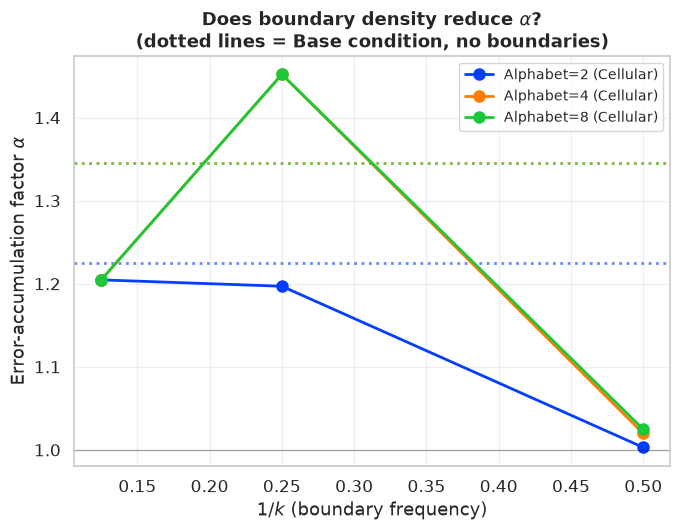

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import curve_fit
import os

# ============================================================
# SK SPIN-GLASS FIT
# ============================================================
# Hou, Zhou, Hu, Chen, You, Qi -- "How Focused Are LLMs? A Quantitative
# Study via Repetitive Deterministic Prediction Tasks" (arXiv:2511.00763).
#
# Eq. 14:  SAR(N) = exp(-beta0 * N * alpha**(N-1))
#   beta0 = intrinsic per-token error rate
#   alpha = error-accumulation factor (alpha > 1 produces the cliff;
#           alpha == 1 would just be ordinary per-token exponential decay)
# Eq. 15:  cliff length  N* ~= 1 + log(1/beta0) / log(alpha)
#
# Fit separately per (Alphabet, Method, Interval) so alpha_base and
# alpha_cellular are directly comparable -- this is the notebook's actual
# test of whether "|" boundaries slow the accuracy cliff, stated in the
# same language as the paper instead of just an empirical linear slope.

def sk_model(N, beta0, alpha):
    N = np.asarray(N, dtype=np.float64)
    return np.exp(-beta0 * N * np.power(alpha, N - 1))

def fit_sk(N_vals, sar_vals):
    N_vals = np.asarray(N_vals, dtype=np.float64)
    sar_vals = np.asarray(sar_vals, dtype=np.float64)
    try:
        popt, _ = curve_fit(
            sk_model, N_vals, sar_vals,
            p0=[0.05, 1.2], bounds=([1e-6, 1.0 + 1e-6], [1.0, 5.0]), maxfev=20000,
        )
        beta0, alpha = popt
        n_star = 1 + np.log(1.0 / beta0) / np.log(alpha) if alpha > 1 else np.inf
        return beta0, alpha, n_star
    except RuntimeError:
        return np.nan, np.nan, np.nan

df_sk = pd.read_csv(os.path.join(RESULTS_DIR, "thermodynamics_grid.csv"))

sk_results = []
for grp in sorted(df_sk['Alphabet_Size'].unique()):
    sub_G = df_sk[df_sk['Alphabet_Size'] == grp]
    for method, sub_M in sub_G.groupby('Method'):
        for interval, sub_I in sub_M.groupby('Interval'):
            per_N = sub_I.groupby('Seq_Length')['SAR'].mean().reset_index()
            if len(per_N) < 3:  # need enough distinct N to fit 2 free params
                continue
            beta0, alpha, n_star = fit_sk(per_N['Seq_Length'], per_N['SAR'])
            sk_results.append({
                'Alphabet_Size': grp, 'Method': method, 'Interval': interval,
                'Beta0': beta0, 'Alpha': alpha, 'N_star': n_star,
                'N_points': len(per_N),
            })

sk_df = pd.DataFrame(sk_results)
print("--- SK MODEL FIT: beta0 (intrinsic error rate), alpha (error accumulation), N* (cliff length) ---")
print(sk_df.round(4).to_string(index=False))
sk_df.to_csv(os.path.join(RESULTS_DIR, "thermodynamics_sk_fit.csv"), index=False)

# --- Headline comparison: does alpha drop from Base to Cellular? ---
base_alpha = sk_df[sk_df['Method'] == 'Base'].set_index('Alphabet_Size')['Alpha']
cell_alpha_mean = (
    sk_df[sk_df['Method'] == 'Cellular_Bounds']
    .groupby('Alphabet_Size')['Alpha']
    .mean()
)
print("\n--- ALPHA: Base vs mean(Cellular) per Alphabet ---")
for grp in sorted(set(base_alpha.index) & set(cell_alpha_mean.index)):
    b, c = base_alpha[grp], cell_alpha_mean[grp]
    pct = 100 * (b - c) / b if b else float('nan')
    print(f"Alphabet={grp}: alpha_base={b:.4f}  alpha_cellular_mean={c:.4f}  "
          f"({'-' if pct >= 0 else '+'}{abs(pct):.1f}% {'reduction' if pct >= 0 else 'increase'})")

# --- Plot: alpha vs boundary density (Inv_K), Base shown as a reference line ---
sk_df['Inv_K'] = sk_df['Interval'].apply(lambda k: 0.0 if k == 0 else 1.0 / k)
groups = sorted(sk_df['Alphabet_Size'].unique())
palette = sns.color_palette("bright", n_colors=len(groups))
colors = {g: c for g, c in zip(groups, palette)}

sns.set_theme(style="whitegrid", font_scale=1.1)
fig, ax = plt.subplots(figsize=(7, 5.5))
for grp in groups:
    sub = sk_df[(sk_df['Alphabet_Size'] == grp) & (sk_df['Method'] == 'Cellular_Bounds')].sort_values('Inv_K')
    if len(sub):
        ax.plot(sub['Inv_K'], sub['Alpha'], marker='o', markersize=8, linewidth=2,
                color=colors[grp], label=f'Alphabet={grp} (Cellular)')
    base_row = sk_df[(sk_df['Alphabet_Size'] == grp) & (sk_df['Method'] == 'Base')]
    if len(base_row):
        ax.axhline(base_row['Alpha'].iloc[0], color=colors[grp], linestyle=':', alpha=0.6, linewidth=2)

ax.axhline(1.0, color='black', linestyle='-', alpha=0.3, linewidth=1)
ax.set_xlabel('$1/k$ (boundary frequency)', fontsize=13)
ax.set_ylabel(r'Error-accumulation factor $\alpha$', fontsize=13)
ax.set_title('Does boundary density reduce $\\alpha$?\n(dotted lines = Base condition, no boundaries)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plot_path = os.path.join(RESULTS_DIR, 'thermodynamics_sk_alpha_vs_density.png')
plt.savefig(plot_path, dpi=300, bbox_inches='tight')
print(f"\nSaved plot to {plot_path}")
plt.show()

# running sum modulo M over digits

In [8]:
# ============================================================
# RUNNING SUM MODULO M -- TASK ENGINE + GRID SEARCH
# ============================================================
# Complements the cyclic-shift task above: that task is purely
# position-local (each output digit depends only on the matching
# input digit), while this task requires tracking a running/
# cumulative state across the whole sequence. It is a better test
# of whether the "|" cell boundaries help or hurt long-range state
# tracking, since the true running sum must persist across
# boundaries rather than reset at each one.
#
# Reuses the `model` / `tokenizer` already loaded above -- no reload.

import pandas as pd
import numpy as np
import random
import itertools
import torch
import os
from tqdm import tqdm

# --- 1. THE PARAMETER SPACE ---
MODULI = [2, 4, 8]
SEQUENCE_LENGTHS = [4, 8, 16, 32, 64, 128, 256]
# Runtime note (measured on an A100): each generate() call costs roughly
# max_new_tokens / 34 seconds. At N=256 (~400 new tokens) that's ~12s/call;
# the full grid at this length list adds ~1.5h beyond the N<=32 baseline.
# Trim this list or TRIALS_T below for a faster pass.
PERIODIC_INTERVALS = [0, 2, 4, 8]   # 0 = Base
API_TEMPERATURES = [0.0]
TRIALS_T = 20

GLOBAL_SEED = 42
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)
torch.manual_seed(GLOBAL_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(GLOBAL_SEED)

# --- 2. TASK ENGINE ---
class ModSumTaskEngine:
    def __init__(self, modulus):
        self.modulus = modulus
        self.digits = [str(i) for i in range(modulus)]

    def generate_raw_input(self, length, rng=None):
        if rng is None:
            rng = random
        return rng.choices(self.digits, k=length)

    def _running_sum_digits(self, raw_input):
        running = 0
        out = []
        for d in raw_input:
            running = (running + int(d)) % self.modulus
            out.append(str(running))
        return out

    def build_base_from_raw(self, raw_input):
        input_str = "".join(raw_input)
        output_str = "".join(self._running_sum_digits(raw_input))

        prompt = f"""You are a deterministic sequence transformer.
Task: Running sum modulo {self.modulus}.
Digits: {', '.join(self.digits)}
Rule: At each position, output the cumulative sum of all digits from the start of the sequence up to and including that position, taken modulo {self.modulus}.
Constraint: Output ONLY the transformed string, one output digit per input digit.
No spaces, no explanations.

Input: {input_str}
Output: """
        return input_str, output_str, prompt

    def build_cellular_from_raw(self, raw_input, interval):
        running_digits = self._running_sum_digits(raw_input)

        input_w_bounds = ""
        output_w_bounds = ""
        for i, (d, out_d) in enumerate(zip(raw_input, running_digits)):
            input_w_bounds += d
            output_w_bounds += out_d
            if interval > 0 and (i + 1) % interval == 0 and i != len(raw_input) - 1:
                input_w_bounds += "|"
                output_w_bounds += "|"

        prompt = f"""You are a deterministic sequence transformer.
Task: Running sum modulo {self.modulus}.
Digits: {', '.join(self.digits)}
Rule: At each position, output the cumulative sum of ALL digits seen so far since the very start of the sequence, taken modulo {self.modulus}.
Constraint: The input contains vertical bars (|). These are structural boundaries only -- DO NOT reset the running sum at a boundary, and DO NOT shift the boundary itself. Copy each boundary exactly to the output.
No spaces, no explanations.

Input: {input_w_bounds}
Output: """
        return input_w_bounds, output_w_bounds, prompt

engines = {M: ModSumTaskEngine(M) for M in MODULI}

# --- 3. PREGENERATE SHARED RAW SEQUENCES ---
shared_sequences = {}
for M in MODULI:
    engine = engines[M]
    for N in SEQUENCE_LENGTHS:
        for t in range(TRIALS_T):
            local_seed = 20_000 * M + 100 * N + t
            rng = random.Random(local_seed)
            shared_sequences[(M, N, t)] = engine.generate_raw_input(N, rng=rng)

print(f"Pregenerated {len(shared_sequences)} shared raw sequences.")

# --- 4. WORKER FUNCTION FOR A SINGLE TRIAL ---
def run_single_modsum_trial(task_params):
    T_api, M, N, k, t = task_params
    engine = engines[M]
    method = "Base" if k == 0 else "Cellular_Bounds"

    raw_input = shared_sequences[(M, N, t)]

    if method == "Base":
        inp, truth, prompt = engine.build_base_from_raw(raw_input)
    else:
        inp, truth, prompt = engine.build_cellular_from_raw(raw_input, interval=k)

    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    max_tokens_needed = int(N * 1.5) + 20

    do_sample = T_api > 0.0
    temp_val = T_api if do_sample else None

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_tokens_needed,
            temperature=temp_val,
            do_sample=do_sample,
            pad_token_id=tokenizer.eos_token_id
        )

    full_response = tokenizer.decode(outputs[0], skip_special_tokens=True)
    pred = full_response[len(prompt):].strip()
    pred = pred.split("Explanation")[0].split("\n")[0].strip()

    if method == "Cellular_Bounds":
        clean_pred = pred.replace("|", "").replace(" ", "").replace("\n", "")
        clean_truth = truth.replace("|", "")
    else:
        clean_pred = pred.replace(" ", "").replace("\n", "")
        clean_truth = truth

    clean_pred = clean_pred[:len(clean_truth)]

    binary_series = []
    for i in range(len(clean_truth)):
        if i < len(clean_pred) and clean_pred[i] == clean_truth[i]:
            binary_series.append(1)
        else:
            binary_series.append(0)

    tar = sum(binary_series) / len(clean_truth) if len(clean_truth) > 0 else 0.0
    sar = 1.0 if (
        len(binary_series) == len(clean_truth)
        and sum(binary_series) == len(binary_series)
    ) else 0.0
    first_error = binary_series.index(0) if 0 in binary_series else len(binary_series)

    return {
        "API_Temp": T_api,
        "Modulus": M,
        "Method": method,
        "Interval": k,
        "Seq_Length": N,
        "Trial": t,
        "Shared_Sequence": "".join(raw_input),
        "TAR": tar,
        "SAR": sar,
        "First_Error_Pos": first_error,
        "Input_Given": inp,
        "Ground_Truth": clean_truth,
        "LLM_Output": clean_pred
    }

# --- 5. MAIN EXPERIMENT SETUP ---
modsum_tasks = list(itertools.product(
    API_TEMPERATURES,
    MODULI,
    SEQUENCE_LENGTHS,
    PERIODIC_INTERVALS,
    range(TRIALS_T)
))

filtered_modsum_tasks = [task for task in modsum_tasks if task[3] == 0 or task[3] < task[2]]

total_calls = len(filtered_modsum_tasks)
print(f"\nStarting Running-Sum-Mod-M Grid Search with 7B Model: {total_calls} total evaluations.")

all_modsum_results = []
for task in tqdm(filtered_modsum_tasks, total=total_calls, desc="Generating"):
    try:
        result = run_single_modsum_trial(task)
        all_modsum_results.append(result)
    except Exception as exc:
        print(f"Task failed: {task} | Error: {exc}")

# --- 6. SAVE & SUMMARIZE ---
df = pd.DataFrame(all_modsum_results)

csv_filename = os.path.join(RESULTS_DIR, "running_modsum_grid.csv")
df.to_csv(csv_filename, index=False)
print(f"\nExperiment complete. Saved to '{csv_filename}'")

summary = (
    df.groupby(["Modulus", "Seq_Length", "Method"])[["TAR", "SAR"]]
      .mean()
      .reset_index()
)
print("\n--- AVERAGE ACCURACY BY MODULUS & LENGTH ---")
print(summary.to_string(index=False))

Pregenerated 420 shared raw sequences.

Starting Running-Sum-Mod-M Grid Search with 7B Model: 1500 total evaluations.


Generating:   0%|          | 0/1500 [00:00<?, ?it/s]

Generating:   0%|          | 1/1500 [00:00<18:29,  1.35it/s]

Generating:   0%|          | 2/1500 [00:01<18:26,  1.35it/s]

Generating:   0%|          | 3/1500 [00:02<18:25,  1.35it/s]

...

Generating: 100%|█████████▉| 1498/1500 [1:39:20<00:23, 11.54s/it]

Generating: 100%|█████████▉| 1499/1500 [1:39:31<00:11, 11.55s/it]

Generating: 100%|██████████| 1500/1500 [1:39:43<00:00, 11.56s/it]

Generating: 100%|██████████| 1500/1500 [1:39:43<00:00,  3.99s/it]


Experiment complete. Saved to 'results/Qwen2.5-7B-Instruct/running_modsum_grid.csv'

--- AVERAGE ACCURACY BY MODULUS & LENGTH ---
 Modulus  Seq_Length          Method      TAR  SAR
       2           4            Base 0.537500 0.05
       2           4 Cellular_Bounds 0.362500 0.00
       2           8            Base 0.468750 0.00
       2           8 Cellular_Bounds 0.453125 0.00
       2          16            Base 0.468750 0.00
       2          16 Cellular_Bounds 0.400000 0.00
       2          32            Base 0.481250 0.00
       2          32 Cellular_Bounds 0.467187 0.00
       2          64            Base 0.489844 0.00
       2          64 Cellular_Bounds 0.479427 0.00
       2         128            Base 0.481641 0.00
       2         128 Cellular_Bounds 0.483203 0.00
       2         256            Base 0.492969 0.00
       2         256 Cellular_Bounds 0.480339 0.00
       4           4            Base 0.475000 0.05
       4           4 Cellular_Bounds 0.125000 0.00
  

    Seq_Length  Modulus  Interval    TAR  SAR
40           8        2         0  0.625  0.0
41           8        2         0  0.500  0.0
42           8        2         0  0.500  0.0
43           8        2         0  0.375  0.0
44           8        2         0  0.875  0.0
45           8        2         0  0.250  0.0
46           8        2         0  0.500  0.0
47           8        2         0  0.375  0.0
48           8        2         0  0.375  0.0
49           8        2         0  0.500  0.0
50           8        2         0  0.500  0.0
51           8        2         0  0.500  0.0
52           8        2         0  0.500  0.0
53           8        2         0  0.375  0.0
54           8        2         0  0.500  0.0
55           8        2         0  0.500  0.0
56           8        2         0  0.500  0.0
57           8        2         0  0.250  0.0
58           8        2         0  0.500  0.0
59           8        2         0  0.375  0.0


Saved plot to results/Qwen2.5-7B-Instruct/running_modsum_scaling_law_N8_plus.png


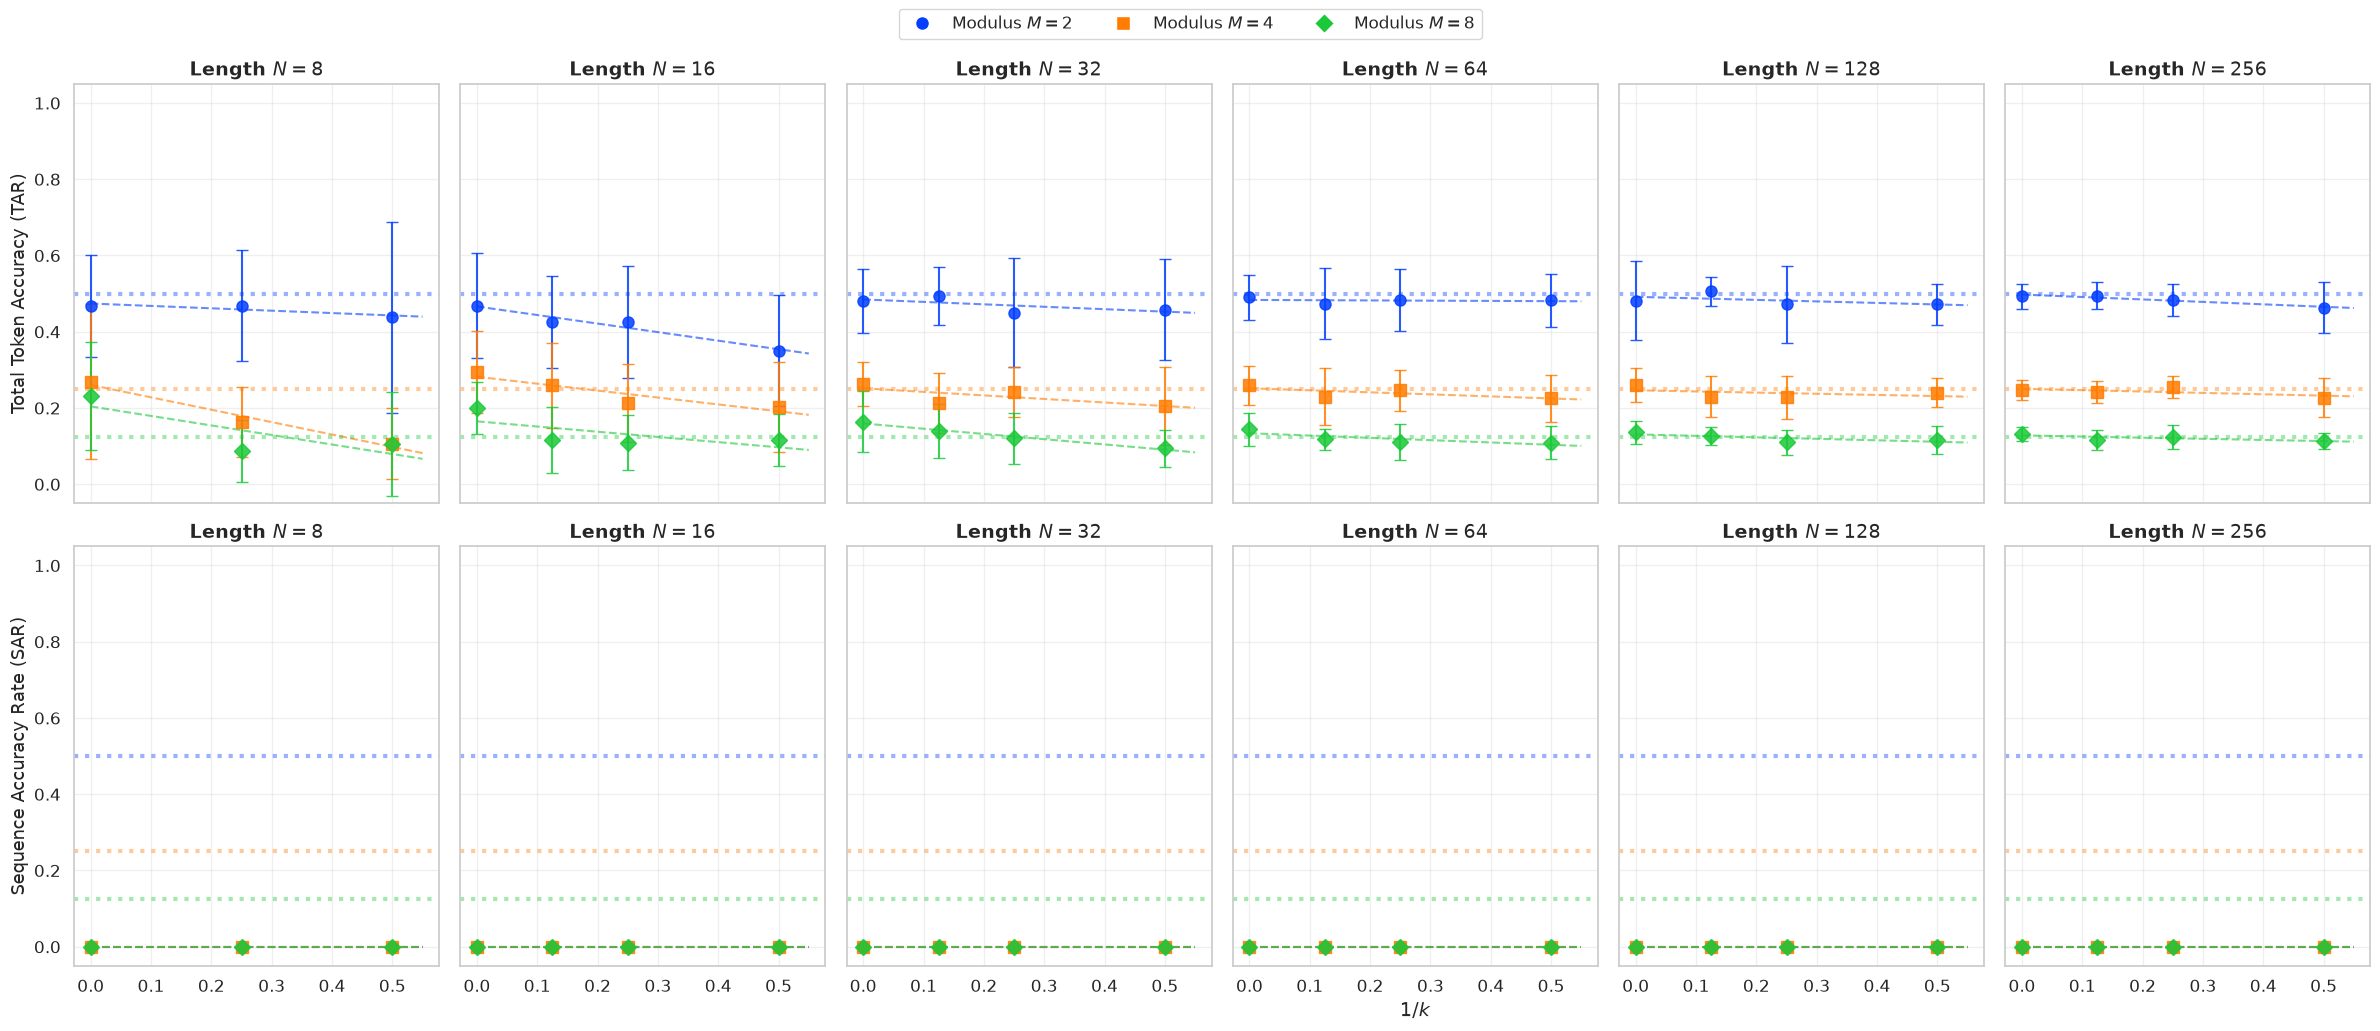


--- SCALING LAW REGRESSION (N >= 8), TAR and SAR ---

TAR:
Seq_Length    8      16     32     64     128    256
Modulus                                             
2           0.750  0.943  0.452  0.042  0.274  0.913
4           0.969  0.839  0.537  0.524  0.180  0.418
8           0.640  0.452  0.976  0.657  0.529  0.553

SAR:
Empty DataFrame
Columns: []
Index: []

--- FULL REGRESSION RESULTS ---
Metric  Seq_Length  Modulus  Slope  Intercept  R_squared  P_value
   TAR           8        2 -0.062      0.474      0.750    0.333
   TAR           8        4 -0.325      0.260      0.969    0.112
   TAR           8        8 -0.250      0.204      0.640    0.410
   TAR          16        2 -0.224      0.466      0.943    0.029
   TAR          16        4 -0.181      0.282      0.839    0.084
   TAR          16        8 -0.136      0.165      0.452    0.328
   TAR          32        2 -0.064      0.485      0.452    0.328
   TAR          32        4 -0.093      0.252      0.537    0.268
   T

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
import seaborn as sns
import os

# --- 1. LOAD DATA ---
file_path = os.path.join(RESULTS_DIR, "running_modsum_grid.csv")
df = pd.read_csv(file_path)

# Robustly handle column names
if 'Accuracy' in df.columns and 'TAR' not in df.columns:
    df['TAR'] = df['Accuracy']
elif 'TAR' not in df.columns:
    raise ValueError("Dataset missing 'TAR' or 'Accuracy' column.")

if 'Modulus' not in df.columns:
    raise ValueError("Dataset missing 'Modulus' column.")

# --- 2. CALCULATE 1/k ---
# Base case (k=0) gets Inv_K = 0
df['Inv_K'] = df['Interval'].apply(lambda k: 0.0 if k == 0 else 1.0 / k)

# Optional filter
df = df[df['Seq_Length'] >= 8]

# Mean AND std (across the 20 trials per condition) for both TAR and SAR --
# SAR (whole-sequence exact match) is the paper's headline "accuracy cliff"
# metric, TAR (per-token accuracy) is the softer companion metric.
summary = (
    df.groupby(['Seq_Length', 'Modulus', 'Inv_K'])[['TAR', 'SAR']]
      .agg(['mean', 'std'])
)
summary.columns = ['_'.join(c) for c in summary.columns]
summary = summary.reset_index().sort_values(['Seq_Length', 'Modulus', 'Inv_K'])
summary[['TAR_std', 'SAR_std']] = summary[['TAR_std', 'SAR_std']].fillna(0.0)

print(df[['Seq_Length', 'Modulus', 'Interval', 'TAR', 'SAR']].head(20))

# --- 3. PLOTTING SETUP (TAR on top row, SAR on bottom row) ---
seq_lengths = sorted(summary['Seq_Length'].unique())
moduli = sorted(summary['Modulus'].unique())
num_lengths = len(seq_lengths)

sns.set_theme(style="whitegrid", font_scale=1.1)

palette = sns.color_palette("bright", n_colors=len(moduli))
colors = {M: col for M, col in zip(moduli, palette)}
marker_list = ['o', 's', 'D', '^', 'v', '<', '>']
markers = {M: marker_list[i % len(marker_list)] for i, M in enumerate(moduli)}

fig, axes = plt.subplots(2, max(num_lengths, 1), figsize=(4 * max(num_lengths, 1), 10),
                          sharex=True, sharey=True, squeeze=False)

regression_results = []

# --- 4. PLOT EACH SEQUENCE LENGTH, EACH METRIC ---
for row, (metric, ylabel) in enumerate([('TAR', 'Total Token Accuracy (TAR)'),
                                         ('SAR', 'Sequence Accuracy Rate (SAR)')]):
    for i, N in enumerate(seq_lengths):
        ax = axes[row][i]
        sub_N = summary[summary['Seq_Length'] == N]

        for M in moduli:
            sub_M = sub_N[sub_N['Modulus'] == M]

            if len(sub_M) < 2:
                continue

            inv_k_vals = sub_M['Inv_K'].values
            metric_vals = sub_M[f'{metric}_mean'].values
            metric_err = sub_M[f'{metric}_std'].values

            slope, intercept, r_value, p_value, std_err = linregress(inv_k_vals, metric_vals)

            regression_results.append({
                'Metric': metric,
                'Seq_Length': N,
                'Modulus': M,
                'Slope': slope,
                'Intercept': intercept,
                'R_squared': r_value ** 2,
                'P_value': p_value
            })

            # Chance baseline: 1/M
            ax.axhline(1.0 / M, color=colors[M], linestyle=':', alpha=0.4, linewidth=3)

            # Points with error bars (std across the 20 trials)
            ax.errorbar(
                inv_k_vals, metric_vals, yerr=metric_err,
                fmt=markers[M], color=colors[M], markersize=8, alpha=0.85,
                capsize=4, linestyle='none'
            )

            # Fit line
            x_fit = np.linspace(0, max(inv_k_vals) * 1.1, 100)
            y_fit = slope * x_fit + intercept
            ax.plot(x_fit, y_fit, linestyle='--', color=colors[M], alpha=0.6, linewidth=1.5)

        ax.set_title(f'Length $N = {N}$', fontsize=14, fontweight='bold')
        ax.set_ylim(-0.05, 1.05)
        ax.grid(True, alpha=0.3)

        if i == 0:
            ax.set_ylabel(ylabel, fontsize=13)
        if row == 1 and i == num_lengths // 2:
            ax.set_xlabel('$1/k$', fontsize=14)

# --- 5. LEGEND ---
handles = [
    plt.Line2D([0], [0], marker=markers[M], color='w', markerfacecolor=colors[M],
               markersize=10, label=f'Modulus $M={M}$')
    for M in moduli
]

fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 1.04), ncol=len(moduli), fontsize=12)

plt.tight_layout()
plot_path = os.path.join(RESULTS_DIR, 'running_modsum_scaling_law_N8_plus.png')
plt.savefig(plot_path, bbox_inches='tight', dpi=300)
print(f"Saved plot to {plot_path}")
plt.show()

# --- 6. PRINT REGRESSION TABLE ---
print("\n--- SCALING LAW REGRESSION (N >= 8), TAR and SAR ---")
results_df = pd.DataFrame(regression_results).round(3)
for metric in ['TAR', 'SAR']:
    print(f"\n{metric}:")
    pivot = results_df[results_df['Metric'] == metric].pivot_table(
        index='Modulus', columns='Seq_Length', values='R_squared')
    print(pivot)

print("\n--- FULL REGRESSION RESULTS ---")
print(results_df.to_string(index=False))

results_df.to_csv(os.path.join(RESULTS_DIR, "modsum_regression.csv"), index=False)

--- SK MODEL FIT: beta0 (intrinsic error rate), alpha (error accumulation), N* (cliff length) ---
 Modulus          Method  Interval  Beta0  Alpha  N_star  N_points
       2            Base         0 0.3825 1.2510  5.2910         7
       2 Cellular_Bounds         2 0.5363 1.7434  2.1208         7
       2 Cellular_Bounds         4 0.1130 1.4520  6.8458         6
       2 Cellular_Bounds         8 0.0512 1.2046 16.9682         5
       4            Base         0 0.3825 1.2510  5.2910         7
       4 Cellular_Bounds         2 0.5363 1.7434  2.1208         7
       4 Cellular_Bounds         4 0.1130 1.4520  6.8458         6
       4 Cellular_Bounds         8 0.0512 1.2046 16.9682         5
       8            Base         0 0.2364 1.3453  5.8618         7
       8 Cellular_Bounds         2 0.5363 1.7434  2.1208         7
       8 Cellular_Bounds         4 0.1130 1.4520  6.8458         6
       8 Cellular_Bounds         8 0.0512 1.2046 16.9682         5

--- ALPHA: Base vs mean(Cellul


Saved plot to results/Qwen2.5-7B-Instruct/modsum_sk_alpha_vs_density.png


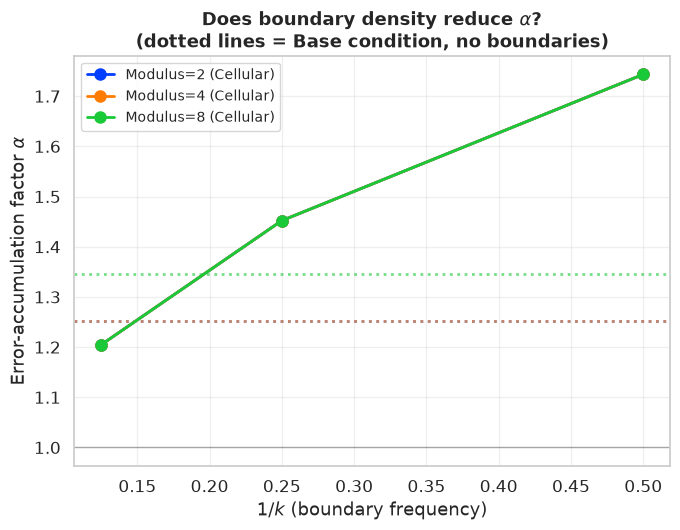

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import curve_fit
import os

# ============================================================
# SK SPIN-GLASS FIT
# ============================================================
# Hou, Zhou, Hu, Chen, You, Qi -- "How Focused Are LLMs? A Quantitative
# Study via Repetitive Deterministic Prediction Tasks" (arXiv:2511.00763).
#
# Eq. 14:  SAR(N) = exp(-beta0 * N * alpha**(N-1))
#   beta0 = intrinsic per-token error rate
#   alpha = error-accumulation factor (alpha > 1 produces the cliff;
#           alpha == 1 would just be ordinary per-token exponential decay)
# Eq. 15:  cliff length  N* ~= 1 + log(1/beta0) / log(alpha)
#
# Fit separately per (Modulus, Method, Interval) so alpha_base and
# alpha_cellular are directly comparable -- this is the notebook's actual
# test of whether "|" boundaries slow the accuracy cliff, stated in the
# same language as the paper instead of just an empirical linear slope.

def sk_model(N, beta0, alpha):
    N = np.asarray(N, dtype=np.float64)
    return np.exp(-beta0 * N * np.power(alpha, N - 1))

def fit_sk(N_vals, sar_vals):
    N_vals = np.asarray(N_vals, dtype=np.float64)
    sar_vals = np.asarray(sar_vals, dtype=np.float64)
    try:
        popt, _ = curve_fit(
            sk_model, N_vals, sar_vals,
            p0=[0.05, 1.2], bounds=([1e-6, 1.0 + 1e-6], [1.0, 5.0]), maxfev=20000,
        )
        beta0, alpha = popt
        n_star = 1 + np.log(1.0 / beta0) / np.log(alpha) if alpha > 1 else np.inf
        return beta0, alpha, n_star
    except RuntimeError:
        return np.nan, np.nan, np.nan

df_sk = pd.read_csv(os.path.join(RESULTS_DIR, "running_modsum_grid.csv"))

sk_results = []
for grp in sorted(df_sk['Modulus'].unique()):
    sub_G = df_sk[df_sk['Modulus'] == grp]
    for method, sub_M in sub_G.groupby('Method'):
        for interval, sub_I in sub_M.groupby('Interval'):
            per_N = sub_I.groupby('Seq_Length')['SAR'].mean().reset_index()
            if len(per_N) < 3:  # need enough distinct N to fit 2 free params
                continue
            beta0, alpha, n_star = fit_sk(per_N['Seq_Length'], per_N['SAR'])
            sk_results.append({
                'Modulus': grp, 'Method': method, 'Interval': interval,
                'Beta0': beta0, 'Alpha': alpha, 'N_star': n_star,
                'N_points': len(per_N),
            })

sk_df = pd.DataFrame(sk_results)
print("--- SK MODEL FIT: beta0 (intrinsic error rate), alpha (error accumulation), N* (cliff length) ---")
print(sk_df.round(4).to_string(index=False))
sk_df.to_csv(os.path.join(RESULTS_DIR, "modsum_sk_fit.csv"), index=False)

# --- Headline comparison: does alpha drop from Base to Cellular? ---
base_alpha = sk_df[sk_df['Method'] == 'Base'].set_index('Modulus')['Alpha']
cell_alpha_mean = (
    sk_df[sk_df['Method'] == 'Cellular_Bounds']
    .groupby('Modulus')['Alpha']
    .mean()
)
print("\n--- ALPHA: Base vs mean(Cellular) per Modulus ---")
for grp in sorted(set(base_alpha.index) & set(cell_alpha_mean.index)):
    b, c = base_alpha[grp], cell_alpha_mean[grp]
    pct = 100 * (b - c) / b if b else float('nan')
    print(f"Modulus={grp}: alpha_base={b:.4f}  alpha_cellular_mean={c:.4f}  "
          f"({'-' if pct >= 0 else '+'}{abs(pct):.1f}% {'reduction' if pct >= 0 else 'increase'})")

# --- Plot: alpha vs boundary density (Inv_K), Base shown as a reference line ---
sk_df['Inv_K'] = sk_df['Interval'].apply(lambda k: 0.0 if k == 0 else 1.0 / k)
groups = sorted(sk_df['Modulus'].unique())
palette = sns.color_palette("bright", n_colors=len(groups))
colors = {g: c for g, c in zip(groups, palette)}

sns.set_theme(style="whitegrid", font_scale=1.1)
fig, ax = plt.subplots(figsize=(7, 5.5))
for grp in groups:
    sub = sk_df[(sk_df['Modulus'] == grp) & (sk_df['Method'] == 'Cellular_Bounds')].sort_values('Inv_K')
    if len(sub):
        ax.plot(sub['Inv_K'], sub['Alpha'], marker='o', markersize=8, linewidth=2,
                color=colors[grp], label=f'Modulus={grp} (Cellular)')
    base_row = sk_df[(sk_df['Modulus'] == grp) & (sk_df['Method'] == 'Base')]
    if len(base_row):
        ax.axhline(base_row['Alpha'].iloc[0], color=colors[grp], linestyle=':', alpha=0.6, linewidth=2)

ax.axhline(1.0, color='black', linestyle='-', alpha=0.3, linewidth=1)
ax.set_xlabel('$1/k$ (boundary frequency)', fontsize=13)
ax.set_ylabel(r'Error-accumulation factor $\alpha$', fontsize=13)
ax.set_title('Does boundary density reduce $\\alpha$?\n(dotted lines = Base condition, no boundaries)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plot_path = os.path.join(RESULTS_DIR, 'modsum_sk_alpha_vs_density.png')
plt.savefig(plot_path, dpi=300, bbox_inches='tight')
print(f"\nSaved plot to {plot_path}")
plt.show()

# Cyclic-Shift vs Running-Sum-Mod-M Comparison

--- SAR ~ 1/k SLOPE BY TASK, GROUP, SEQ_LENGTH ---
                          Task  Group  Seq_Length  Slope  R_squared
          Cyclic Shift (local)      2           8  1.400      0.902
          Cyclic Shift (local)      4           8  0.100      0.750
          Cyclic Shift (local)      8           8  0.200      0.750
          Cyclic Shift (local)      2          16  1.131      0.771
          Cyclic Shift (local)      4          16  0.000        NaN
          Cyclic Shift (local)      8          16  0.000        NaN
          Cyclic Shift (local)      2          32  0.823      0.771
          Cyclic Shift (local)      4          32  0.000        NaN
          Cyclic Shift (local)      8          32  0.000        NaN
          Cyclic Shift (local)      2          64  0.000        NaN
          Cyclic Shift (local)      4          64  0.000        NaN
          Cyclic Shift (local)      8          64  0.000        NaN
          Cyclic Shift (local)      2         128  0.000        N


Saved plot to results/Qwen2.5-7B-Instruct/cyclic_vs_modsum_slope_comparison.png


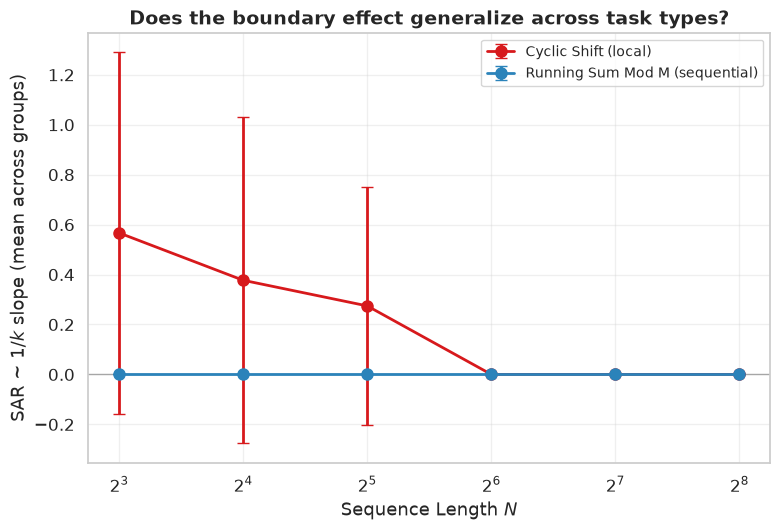


--- SAME-SIGN SLOPE ACROSS TASKS, PER SEQ_LENGTH ---
Seq_Length
8      False
16     False
32     False
64     False
128    False
256    False
dtype: bool

Agrees on direction at 0/6 sequence lengths.


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# ============================================================
# CYCLIC-SHIFT vs RUNNING-SUM-MOD-M: DOES THE BOUNDARY EFFECT GENERALIZE?
# ============================================================
# Cyclic shift is a purely position-local task (each output token depends
# only on the matching input token -- no dependency between positions).
# Running-sum-mod-M requires tracking state across the *whole* sequence.
# Comparing their SAR ~ 1/k slopes tests whether the "|" boundary effect
# measured throughout this notebook is specific to one task's dependency
# structure, or holds across tasks that need very different kinds of
# reasoning. Positive slope = SAR rises with boundary density (boundaries
# help); negative = boundaries hurt.

thermo_reg = pd.read_csv(os.path.join(RESULTS_DIR, "thermodynamics_regression.csv"))
modsum_reg = pd.read_csv(os.path.join(RESULTS_DIR, "modsum_regression.csv"))

thermo_sar = thermo_reg[thermo_reg['Metric'] == 'SAR'].rename(columns={'Alphabet': 'Group'}).copy()
thermo_sar['Task'] = 'Cyclic Shift (local)'
modsum_sar = modsum_reg[modsum_reg['Metric'] == 'SAR'].rename(columns={'Modulus': 'Group'}).copy()
modsum_sar['Task'] = 'Running Sum Mod M (sequential)'

combined = pd.concat([
    thermo_sar[['Task', 'Group', 'Seq_Length', 'Slope', 'R_squared']],
    modsum_sar[['Task', 'Group', 'Seq_Length', 'Slope', 'R_squared']],
], ignore_index=True)

print("--- SAR ~ 1/k SLOPE BY TASK, GROUP, SEQ_LENGTH ---")
print(combined.round(4).to_string(index=False))

# --- Per-task summary: mean slope across groups, by sequence length ---
summary = combined.groupby(['Task', 'Seq_Length'])['Slope'].agg(['mean', 'std']).reset_index()
summary['std'] = summary['std'].fillna(0.0)
print("\n--- MEAN SLOPE PER TASK, PER SEQ_LENGTH ---")
print(summary.round(4).to_string(index=False))

sns.set_theme(style="whitegrid", font_scale=1.1)
fig, ax = plt.subplots(figsize=(8, 5.5))
palette = {'Cyclic Shift (local)': '#d7191c', 'Running Sum Mod M (sequential)': '#2b83ba'}
for task, sub in summary.groupby('Task'):
    sub = sub.sort_values('Seq_Length')
    ax.errorbar(sub['Seq_Length'], sub['mean'], yerr=sub['std'],
                marker='o', markersize=8, linewidth=2, capsize=4,
                color=palette.get(task), label=task)

ax.axhline(0.0, color='black', linestyle='-', alpha=0.3, linewidth=1)
ax.set_xscale('log', base=2)
ax.set_xlabel('Sequence Length $N$', fontsize=13)
ax.set_ylabel('SAR ~ $1/k$ slope (mean across groups)', fontsize=13)
ax.set_title('Does the boundary effect generalize across task types?', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plot_path = os.path.join(RESULTS_DIR, 'cyclic_vs_modsum_slope_comparison.png')
plt.savefig(plot_path, dpi=300, bbox_inches='tight')
print(f"\nSaved plot to {plot_path}")
plt.show()

# --- Headline: same sign (both help or both hurt) at each N? ---
pivot = summary.pivot(index='Seq_Length', columns='Task', values='mean')
if pivot.shape[1] == 2:
    same_sign = (pivot.iloc[:, 0] * pivot.iloc[:, 1]) > 0
    print("\n--- SAME-SIGN SLOPE ACROSS TASKS, PER SEQ_LENGTH ---")
    print(same_sign)
    print(f"\nAgrees on direction at {same_sign.sum()}/{len(same_sign)} sequence lengths.")

# Attention Analysis

In [12]:
import os
import csv
import random
import torch
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

# ============================================================
# 1. SETUP
# ============================================================

run_id = 0  # representative example id (see SECTION 3 below)

output_dir = RESULTS_DIR  # from the MODEL SELECTION cell -- results/<MODEL_TAG>/

# Reuses the `model` / `tokenizer` already loaded above -- no reload needed.
# (output_attentions is requested per forward-call below instead of at load
# time; the shared model was loaded with attn_implementation="eager" so
# attentions are actually computable.)
model.eval()

num_layers = model.config.num_hidden_layers
num_heads = model.config.num_attention_heads

# Seed the representative-example prompt draw so it's reproducible.
ATTENTION_SEED = 123
random.seed(ATTENTION_SEED)

# ============================================================
# 2. TASK ENGINE
# ============================================================

class TaskEngine:
    def __init__(self, alphabet_size):
        self.alphabet_size = alphabet_size
        self.alphabet = [chr(ord('A') + i) for i in range(alphabet_size)]

    def generate_paired_prompts(self, length, interval, rng=None):
        rng = rng or random
        raw_chars = rng.choices(self.alphabet, k=length)

        base_str = " ".join(raw_chars)
        prompt_base = f"""You are a deterministic sequence transformer.
Task: Cyclic character shift.
Alphabet: {', '.join(self.alphabet)}
Rule: Replace every character with the next one in the alphabet.
Mapping: {self.alphabet[-1]} -> {self.alphabet[0]}, and {self.alphabet[0]} -> {self.alphabet[1]}.
Constraint: The input contains vertical bars (|). These are structural boundaries. DO NOT shift them. Copy them exactly to the output.
No spaces, no explanations.

Input: {base_str}
Output: """

        cellular_w_bounds = []
        for i, char in enumerate(raw_chars):
            cellular_w_bounds.append(char)
            if interval > 0 and (i + 1) % interval == 0 and i != length - 1:
                cellular_w_bounds.append("|")

        cell_str = " ".join(cellular_w_bounds)

        prompt_cell = f"""You are a deterministic sequence transformer.
Task: Cyclic character shift.
Alphabet: {', '.join(self.alphabet)}
Rule: Replace every character with the next one in the alphabet.
Mapping: {self.alphabet[-1]} -> {self.alphabet[0]}, and {self.alphabet[0]} -> {self.alphabet[1]}.
Constraint: The input contains vertical bars (|). These are structural boundaries. DO NOT shift them. Copy them exactly to the output.
No spaces, no explanations.

Input: {cell_str}
Output: """

        return prompt_base, prompt_cell


engine = TaskEngine(alphabet_size=2)
N_length = 16
k_interval = 2
prompt_base, prompt_cell = engine.generate_paired_prompts(
    length=N_length,
    interval=k_interval
)

# ============================================================
# 3. ATTENTION EXTRACTION (FULL TENSOR)
# ============================================================

def extract_all_layers_and_heads(prompt):
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    with torch.no_grad():
        outputs = model(**inputs, output_attentions=True)

    tokens = [tokenizer.decode([t]) for t in inputs.input_ids[0]]

    # Cropping
    try:
        input_idx = next(i for i, t in enumerate(tokens) if 'Input' in t)
        output_idx = next(i for i in range(input_idx, len(tokens)) if 'Output' in tokens[i])

        start_idx = input_idx + 1
        while start_idx < output_idx and tokens[start_idx].strip() in [':', '']:
            start_idx += 1

        end_idx = output_idx
        while end_idx > start_idx and tokens[end_idx - 1].strip() == '':
            end_idx -= 1
    except StopIteration:
        start_idx, end_idx = 0, len(tokens)

    clean_tokens = [t.strip() if t.strip() else '_' for t in tokens[start_idx:end_idx]]

    attentions = outputs.attentions
    seq_len = end_idx - start_idx

    full_tensor = np.zeros(
        (num_layers, num_heads, seq_len, seq_len),
        dtype=np.float32
    )

    for l in range(num_layers):
        layer_attn = attentions[l][0]
        for h in range(num_heads):
            attn_matrix = layer_attn[h].cpu().to(torch.float32).numpy()
            cropped = attn_matrix[start_idx:end_idx, start_idx:end_idx]
            full_tensor[l, h] = cropped

    return full_tensor, clean_tokens


print("\nRunning forward pass for Base Prompt (representative example)...")
attn_base_tensor, tokens_base = extract_all_layers_and_heads(prompt_base)

print("Running forward pass for Cellular Prompt (representative example)...")
attn_cell_tensor, tokens_cell = extract_all_layers_and_heads(prompt_cell)

# ============================================================
# 4. SAVE FULL MATRICES (representative example only -- used by the
#    detailed single-example cells further down: Head Entropy, Network
#    Analysis, Sample Presentation, attention-weight distributions,
#    Correlation Decay)
# ============================================================

print("Saving full attention tensors...")

np.savez_compressed(
    os.path.join(output_dir, f"attention_run_{run_id}.npz"),
    attn_base=attn_base_tensor,
    attn_cell=attn_cell_tensor,
    tokens_base=np.array(tokens_base),
    tokens_cell=np.array(tokens_cell),
    N_length=N_length,
    k_interval=k_interval
)

print("Full tensors saved successfully.\n")

# ============================================================
# 5. MULTI-CONDITION SWEEP (statistics, not just one anecdote)
# ============================================================
# The representative example above is a single (N, k) case. To see whether
# the boundary-sink / entropy effects are systematic -- not an artifact of
# one random draw -- sweep across sequence lengths, boundary intervals, and
# many trials, the same way the "Qwen Scaling" grid search does for
# accuracy. Only scalar metrics (averaged over all layers/heads) are kept
# per condition -- full attention tensors are only saved for the single
# representative example above, to keep storage bounded.

def compute_condition_metrics(attn_base_tensor, attn_cell_tensor, tokens_cell):
    boundary_indices = [i for i, t in enumerate(tokens_cell) if '|' in t]
    eps = 1e-12
    rows = []
    for l in range(num_layers):
        for h in range(num_heads):
            m_base = attn_base_tensor[l, h]
            m_cell = attn_cell_tensor[l, h]

            N_base = m_base.shape[0]
            N_cell = m_cell.shape[0]

            if N_base > 1:
                base_diag = np.mean(np.diag(m_base))
                base_entropy = np.mean(-np.sum(m_base * np.log2(m_base + eps), axis=-1))
                dist_base = np.abs(np.arange(N_base)[:, None] - np.arange(N_base)[None, :]) / N_base
                base_dist = np.mean(np.sum(m_base * dist_base, axis=-1))
            else:
                base_diag = base_entropy = base_dist = 0.0

            if N_cell > 1:
                cell_diag = np.mean(np.diag(m_cell))
                cell_entropy = np.mean(-np.sum(m_cell * np.log2(m_cell + eps), axis=-1))
                dist_cell = np.abs(np.arange(N_cell)[:, None] - np.arange(N_cell)[None, :]) / N_cell
                cell_dist = np.mean(np.sum(m_cell * dist_cell, axis=-1))
                if len(boundary_indices) > 0:
                    cell_boundary = np.mean(np.sum(m_cell[:, boundary_indices], axis=-1))
                else:
                    cell_boundary = 0.0
            else:
                cell_diag = cell_entropy = cell_dist = cell_boundary = 0.0

            rows.append({
                "Base_Diag": base_diag, "Cell_Diag": cell_diag,
                "Base_Entropy": base_entropy, "Cell_Entropy": cell_entropy,
                "Base_Dist": base_dist, "Cell_Dist": cell_dist,
                "Cell_Boundary_Attn": cell_boundary,
            })
    # Average over all (layer, head) pairs -> one summary row per condition
    return pd.DataFrame(rows).mean().to_dict()


# A *fixed* threshold (like the 0.1 the single-example Network Analysis cell
# uses) does not work here: averaging over 28 layers x 28 heads dilutes the
# attention mass, and that dilution gets worse as N grows (a uniform
# attention baseline is already only 1/seq_len). Measured on real examples:
# threshold=0.1 zeroed out 99% of the averaged matrix even at N=16, and any
# *fixed* absolute threshold degenerates back to a near-empty graph again
# once N reaches the hundreds. Instead threshold relative to the uniform-
# attention baseline (1/seq_len) for each matrix -- verified non-degenerate
# (positive edge count, non-zero clustering) from N=8 through N=256.
CLUSTERING_THRESHOLD_MULTIPLIER = 0.5  # threshold = multiplier / seq_len

def compute_condition_clustering(attn_base_tensor, attn_cell_tensor,
                                  multiplier=CLUSTERING_THRESHOLD_MULTIPLIER):
    # Per-(layer,head) clustering for every sweep condition would mean ~28*28
    # graph builds PER condition (~375k total across the full sweep) -- too
    # slow to be worth it. Instead average the attention matrix across all
    # layers/heads into one aggregate network per condition/side, and compute
    # a single clustering coefficient on that. Coarser than the single-example
    # per-layer view in the Network Analysis cell below, but captures the same
    # "does chunking induce more local modularity" question with real N/k
    # statistics instead of one anecdote.
    def clustering_of(m_avg):
        threshold = multiplier / m_avg.shape[0]
        m = m_avg.copy()
        m[m < threshold] = 0.0
        G = nx.from_numpy_array(m, create_using=nx.DiGraph)
        G.remove_edges_from(nx.selfloop_edges(G))  # see the Network Analysis
                                                     # cell for why self-loops
                                                     # must be dropped (NaN fix)
        vals = list(nx.clustering(G, weight='weight').values())
        return np.nanmean(vals) if vals else 0.0

    base_clustering = clustering_of(attn_base_tensor.mean(axis=(0, 1)))
    cell_clustering = clustering_of(attn_cell_tensor.mean(axis=(0, 1)))
    return base_clustering, cell_clustering


SWEEP_SEQUENCE_LENGTHS = [4, 8, 16, 32, 64, 128, 256]
# Runtime note: forward passes stay cheap even at N=256 (measured ~0.05-0.1s
# each on an A100), so the sweep itself is fast (a few minutes). Trim this
# list or SWEEP_TRIALS below if you want a quicker pass.
SWEEP_INTERVALS = [2, 4, 8]   # no 0: a k=0 "cellular" prompt is identical to the base prompt
SWEEP_TRIALS = 20

sweep_conditions = [
    (N, k, t)
    for N in SWEEP_SEQUENCE_LENGTHS
    for k in SWEEP_INTERVALS
    for t in range(SWEEP_TRIALS)
    if k < N
]
print(f"\nStarting attention sweep: {len(sweep_conditions)} conditions "
      f"({len(sweep_conditions) * 2} forward passes)...")

sweep_rows = []
for (N, k, t) in tqdm(sweep_conditions, desc="Attention sweep"):
    # Independent, deterministic seed per condition -- does not disturb the
    # global `random` state used for the representative example above.
    local_seed = 50_000 * N + 100 * k + t
    rng = random.Random(local_seed)

    p_base, p_cell = engine.generate_paired_prompts(length=N, interval=k, rng=rng)
    ab, _ = extract_all_layers_and_heads(p_base)
    ac, tc = extract_all_layers_and_heads(p_cell)

    m = compute_condition_metrics(ab, ac, tc)
    m["Delta_Diag"] = m["Cell_Diag"] - m["Base_Diag"]
    m["Delta_Entropy"] = m["Cell_Entropy"] - m["Base_Entropy"]
    m["Delta_Dist"] = m["Cell_Dist"] - m["Base_Dist"]
    m["Base_Clustering"], m["Cell_Clustering"] = compute_condition_clustering(ab, ac)
    m["Delta_Clustering"] = m["Cell_Clustering"] - m["Base_Clustering"]
    m.update(Seq_Length=N, Interval=k, Trial=t)
    sweep_rows.append(m)

sweep_df = pd.DataFrame(sweep_rows)
sweep_df["Inv_K"] = 1.0 / sweep_df["Interval"]

csv_filename = os.path.join(output_dir, "attention_metrics.csv")
sweep_df.to_csv(csv_filename, index=False)
print(f"\nAttention sweep complete. Saved {len(sweep_df)} condition-level rows to '{csv_filename}'")

summary = (
    sweep_df.groupby(["Seq_Length", "Interval"])[["Cell_Boundary_Attn", "Delta_Entropy", "Delta_Diag"]]
            .mean()
            .reset_index()
)
print("\n--- MEAN ATTENTION METRICS BY (Seq_Length, Interval) ---")
print(summary.to_string(index=False))

# ============================================================
# 6. HEATMAP GENERATION (representative example only, commented out)
# ============================================================

# print("Generating heatmaps...")

# for l in tqdm(range(num_layers), desc="Layers"):
#     for h in range(num_heads):

#         m_base = attn_base_tensor[l, h]
#         m_cell = attn_cell_tensor[l, h]

#         fig, (ax1, ax2, cbar_ax) = plt.subplots(
#             1, 3, figsize=(18, 7),
#             gridspec_kw={'width_ratios': [1, 1, 0.05]}
#         )

#         sns.heatmap(
#             m_base,
#             xticklabels=tokens_base,
#             yticklabels=tokens_base,
#             cmap="rocket",
#             ax=ax1,
#             cbar=False,
#             vmin=0,
#             vmax=1
#         )

#         ax1.set_title(f"Base | Layer {l}, Head {h}")
#         ax1.set_aspect('equal')

#         sns.heatmap(
#             m_cell,
#             xticklabels=tokens_cell,
#             yticklabels=tokens_cell,
#             cmap="rocket",
#             ax=ax2,
#             cbar_ax=cbar_ax,
#             vmin=0,
#             vmax=1
#         )

#         ax2.set_title(f"Cellular | Layer {l}, Head {h}")
#         ax2.set_aspect('equal')

#         if len(boundary_indices) > 0:
#             for b in boundary_indices:
#                 ax2.axvline(x=b, color='cyan', linestyle='--', linewidth=1)
#                 ax2.axhline(y=b, color='cyan', linestyle='--', linewidth=1)

#         plt.tight_layout()

#         filename = os.path.join(
#             output_dir,
#             f"layer_{l:02d}_head_{h:02d}.png"
#         )
#         plt.savefig(filename, dpi=100)
#         plt.close(fig)

# print("Done.")


Running forward pass for Base Prompt (representative example)...
Running forward pass for Cellular Prompt (representative example)...
Saving full attention tensors...


Full tensors saved successfully.


Starting attention sweep: 360 conditions (720 forward passes)...


Attention sweep:   0%|          | 0/360 [00:00<?, ?it/s]

Attention sweep:   0%|          | 1/360 [00:00<01:05,  5.45it/s]

Attention sweep:   1%|          | 2/360 [00:00<01:05,  5.48it/s]

...

Attention sweep:  99%|█████████▉| 358/360 [12:27<00:14,  7.33s/it]

Attention sweep: 100%|█████████▉| 359/360 [12:34<00:07,  7.28s/it]

Attention sweep: 100%|██████████| 360/360 [12:41<00:00,  7.32s/it]

Attention sweep: 100%|██████████| 360/360 [12:41<00:00,  2.12s/it]


Attention sweep complete. Saved 360 condition-level rows to 'results/Qwen2.5-7B-Instruct/attention_metrics.csv'

--- MEAN ATTENTION METRICS BY (Seq_Length, Interval) ---
 Seq_Length  Interval  Cell_Boundary_Attn  Delta_Entropy  Delta_Diag
          4         2            0.058400       0.082399    0.001980
          8         2            0.098570       0.140096   -0.000414
          8         4            0.045404       0.050327    0.001604
         16         2            0.128791       0.182819   -0.001563
         16         4            0.076514       0.091572    0.001671
         16         8            0.035036       0.034926    0.001804
         32         2            0.148701       0.212606   -0.001392
         32         4            0.099980       0.115641    0.001781
         32         8            0.059065       0.052960    0.002336
         64         2            0.160259       0.212815   -0.001702
         64         4            0.113998       0.123447    0.001205
 

In [13]:
import shutil
import os

# The 'results' folder you saw when running 'ls'
source_dir = "results"
# The name of the zip file you want to create
zip_name = "my_attention_results"

if os.path.exists(source_dir):
    # This creates 'my_attention_results.zip'
    shutil.make_archive(zip_name, 'zip', source_dir)
    print(f"✅ Successfully created {zip_name}.zip")
else:
    print(f"❌ Error: The folder '{source_dir}' was not found in this directory.")

✅ Successfully created my_attention_results.zip


# Boudery Sink Analysis

Loaded 360 sweep conditions from 'results/Qwen2.5-7B-Instruct/attention_metrics.csv'
   Seq_Length  Interval  Trial  Cell_Boundary_Attn  Delta_Entropy  Delta_Diag
0           4         2      0            0.060269       0.084222   -0.000600
1           4         2      1            0.056519       0.081236    0.000452
2           4         2      2            0.057850       0.073748    0.000570
3           4         2      3            0.057036       0.084523    0.002128
4           4         2      4            0.057850       0.073748    0.000570
5           4         2      5            0.060887       0.090603    0.005221
6           4         2      6            0.057036       0.084523    0.002128
7           4         2      7            0.056439       0.075884    0.000133
8           4         2      8            0.059079       0.082769    0.001805
9           4         2      9            0.056519       0.081236    0.000452

--- OVERALL (across all conditions) ---
      Cell_Bound

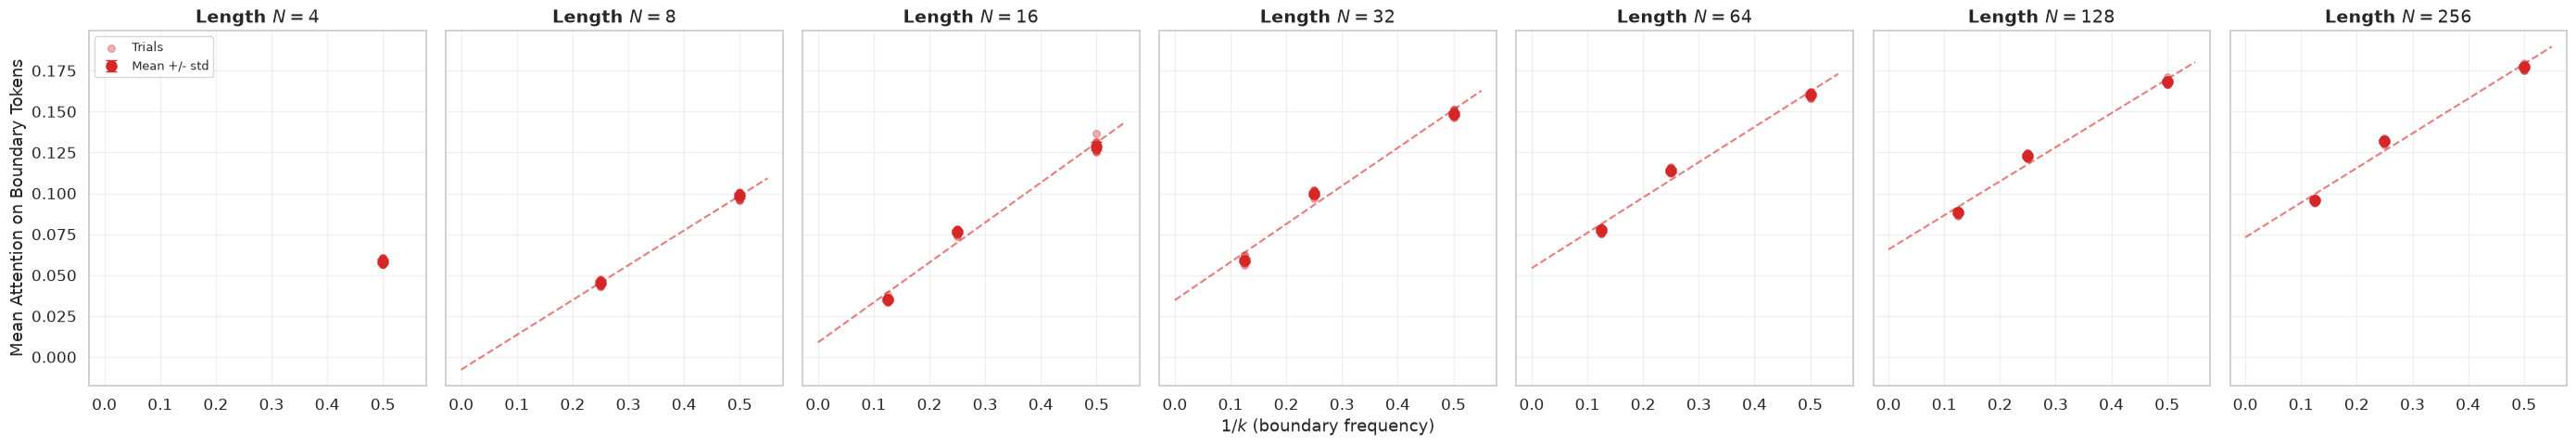


--- BOUNDARY-SINK REGRESSION (Cell_Boundary_Attn ~ Inv_K, by Seq_Length) ---
 Seq_Length  Slope  Intercept  R_squared  P_value
          8 0.2127    -0.0078     0.9972      0.0
         16 0.2442     0.0089     0.9830      0.0
         32 0.2327     0.0347     0.9793      0.0
         64 0.2159     0.0542     0.9839      0.0
        128 0.2082     0.0657     0.9857      0.0
        256 0.2119     0.0731     0.9840      0.0

--- MEAN DELTA (Cellular - Base) BY (Seq_Length, Interval) ---
 Seq_Length  Interval  Delta_Entropy  Delta_Diag  Delta_Dist
          4         2       0.082399    0.001980    0.008944
          8         2       0.140096   -0.000414    0.007366
          8         4       0.050327    0.001604    0.001935
         16         2       0.182819   -0.001563    0.007132
         16         4       0.091572    0.001671    0.002267
         16         8       0.034926    0.001804   -0.000115
         32         2       0.212606   -0.001392    0.006351
         32         

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
import seaborn as sns
import os

# ============================================================
# BOUNDARY SINK ANALYSIS (statistical, across the attention sweep)
# ============================================================
# attention_metrics.csv now holds one row per (Seq_Length, Interval, Trial)
# condition from the sweep in the Attention Analysis setup cell -- not a
# single snapshot. Cell_Boundary_Attn is the average attention mass (across
# all layers/heads) that lands on the "|" boundary tokens; if boundaries
# act as attention sinks, this should be systematically elevated, and grow
# as boundaries get more frequent (larger Inv_K = 1/Interval).

csv_filename = os.path.join(RESULTS_DIR, "attention_metrics.csv")
df = pd.read_csv(csv_filename)

print(f"Loaded {len(df)} sweep conditions from '{csv_filename}'")
print(df[["Seq_Length", "Interval", "Trial", "Cell_Boundary_Attn", "Delta_Entropy", "Delta_Diag"]].head(10))

# --- Overall summary ---
print("\n--- OVERALL (across all conditions) ---")
print(df[["Cell_Boundary_Attn", "Delta_Entropy", "Delta_Diag", "Delta_Dist"]].agg(["mean", "std"]))

# --- Plot: Boundary attention vs 1/k, faceted by sequence length ---
seq_lengths = sorted(df["Seq_Length"].unique())
num_lengths = len(seq_lengths)

sns.set_theme(style="whitegrid", font_scale=1.1)

if num_lengths == 1:
    fig, axes = plt.subplots(1, 1, figsize=(6, 5))
    axes = [axes]
else:
    fig, axes = plt.subplots(1, num_lengths, figsize=(4 * num_lengths, 5), sharex=True, sharey=True)

regression_results = []

for i, N in enumerate(seq_lengths):
    ax = axes[i]
    sub_N = df[df["Seq_Length"] == N]

    # Per-(Interval) mean +/- std across trials, then regress the trial-level points
    summary_N = sub_N.groupby("Inv_K")["Cell_Boundary_Attn"].agg(["mean", "std"]).reset_index()

    ax.scatter(sub_N["Inv_K"], sub_N["Cell_Boundary_Attn"], color="tab:red", alpha=0.35, s=30, label="Trials")
    ax.errorbar(summary_N["Inv_K"], summary_N["mean"], yerr=summary_N["std"],
                fmt="o", color="tab:red", markersize=8, capsize=4, label="Mean +/- std")

    if sub_N["Inv_K"].nunique() >= 2:
        slope, intercept, r_value, p_value, std_err = linregress(sub_N["Inv_K"], sub_N["Cell_Boundary_Attn"])
        regression_results.append({
            "Seq_Length": N, "Slope": slope, "Intercept": intercept,
            "R_squared": r_value ** 2, "P_value": p_value,
        })
        x_fit = np.linspace(0, sub_N["Inv_K"].max() * 1.1, 100)
        y_fit = slope * x_fit + intercept
        ax.plot(x_fit, y_fit, linestyle="--", color="tab:red", alpha=0.6, linewidth=1.5)

    ax.set_title(f"Length $N = {N}$", fontsize=14, fontweight="bold")
    ax.grid(True, alpha=0.3)
    if i == 0:
        ax.set_ylabel("Mean Attention on Boundary Tokens", fontsize=13)
    if i == num_lengths // 2:
        ax.set_xlabel("$1/k$ (boundary frequency)", fontsize=13)

axes[0].legend(fontsize=9, loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "boundary_sink_analysis.png"), bbox_inches="tight", dpi=300)
plt.show()

print("\n--- BOUNDARY-SINK REGRESSION (Cell_Boundary_Attn ~ Inv_K, by Seq_Length) ---")
print(pd.DataFrame(regression_results).round(4).to_string(index=False))

# --- Does chunking also change entropy/diagonal focus, beyond the boundary tokens themselves? ---
delta_summary = (
    df.groupby(["Seq_Length", "Interval"])[["Delta_Entropy", "Delta_Diag", "Delta_Dist"]]
      .mean()
      .reset_index()
      .sort_values(["Seq_Length", "Interval"])
)
print("\n--- MEAN DELTA (Cellular - Base) BY (Seq_Length, Interval) ---")
print(delta_summary.to_string(index=False))

# Head Entropy

Base shape: (28, 28, 16, 16)
Cell shape: (28, 28, 23, 23)
Number of alphabetic tokens in Cellular: 16


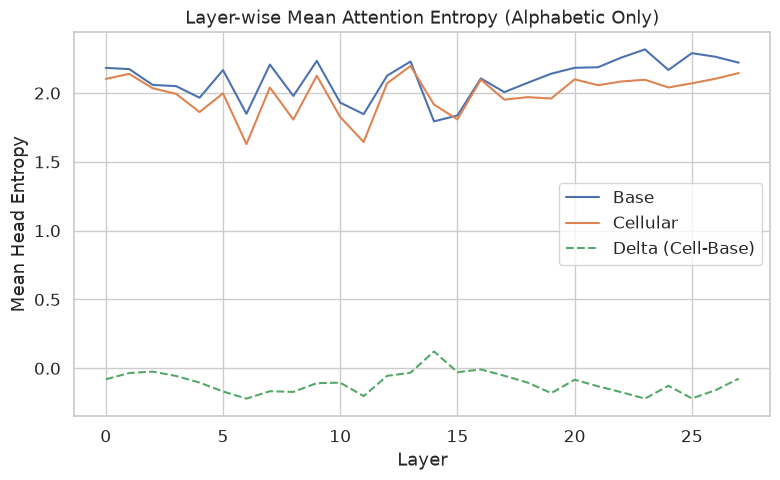

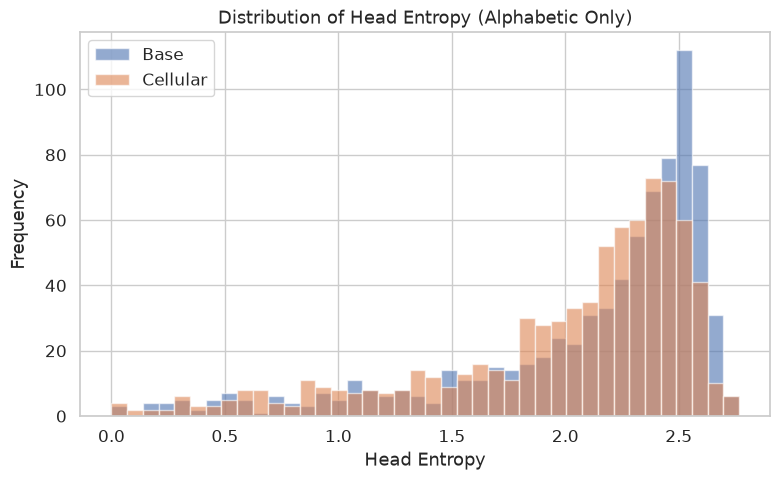

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# ============================================================
# 1. LOAD DATA
# ============================================================

data = np.load(os.path.join(RESULTS_DIR, "attention_run_0.npz"), allow_pickle=True)

attn_base = data["attn_base"]
attn_cell = data["attn_cell"]
tokens_base = data["tokens_base"]
tokens_cell = data["tokens_cell"]

num_layers, num_heads = attn_base.shape[:2]

print("Base shape:", attn_base.shape)
print("Cell shape:", attn_cell.shape)

# ============================================================
# 2. MASK BOUNDARIES and All Zero Heads
# ============================================================

# Create a mask to ignore '|' tokens
mask_cell = np.array([t != '|' for t in tokens_cell])

# Apply mask: crop both rows and columns to alphabetic tokens only
attn_cell_masked = attn_cell[:, :, mask_cell, :][:, :, :, mask_cell]
# Reverse Mask
#attn_cell_masked = attn_cell
print("Number of alphabetic tokens in Cellular:", mask_cell.sum())

# ============================================================
# 3. ENTROPY FUNCTION
# ============================================================
def compute_head_entropy(attn_tensor, ignore=None):
    """
    Returns entropy per (layer, head)
    Output shape: (layers, heads)

    ignore: tuple (layer_index, head_index) to skip, e.g., (27, 10)
    """
    eps = 1e-12
    L, H = attn_tensor.shape[:2]
    entropy_matrix = np.zeros((L, H))

    for l in range(L):
        for h in range(H):
            if ignore is not None and (l, h) == ignore:
                entropy_matrix[l, h] = np.nan
                continue

            m = attn_tensor[l, h]  # (N, N)
            
            # Normalize each row to sum to 1
            row_sums = m.sum(axis=-1, keepdims=True)
            m_norm = m / (row_sums + eps)  # avoid division by zero

            # Compute entropy per row
            row_entropy = -np.sum(m_norm * np.log2(m_norm + eps), axis=-1)
            
            # Average over rows to get head-level entropy
            entropy_matrix[l, h] = np.mean(row_entropy)

    return entropy_matrix
    
# ============================================================
# 4. COMPUTE ENTROPY (with ignored head)
# ============================================================

ignore_layer_head = (1, 1)  # 0-based indexing
ignore_layer_head = None

entropy_base = compute_head_entropy(attn_base, ignore=ignore_layer_head)          
entropy_cell = compute_head_entropy(attn_cell_masked, ignore=ignore_layer_head)

# Compute delta, ignoring the ignored head
delta_entropy = entropy_cell - entropy_base

# ============================================================
# 6. VISUALIZATION 2: LAYER-WISE MEAN ENTROPY
# ============================================================

layer_mean_base = np.mean(entropy_base, axis=1)
layer_mean_cell = np.mean(entropy_cell, axis=1)
layer_mean_delta = np.mean(delta_entropy, axis=1)

plt.figure(figsize=(8, 5))
plt.plot(layer_mean_base, label="Base")
plt.plot(layer_mean_cell, label="Cellular")
plt.plot(layer_mean_delta, label="Delta (Cell-Base)", linestyle="--")
plt.xlabel("Layer")
plt.ylabel("Mean Head Entropy")
plt.title("Layer-wise Mean Attention Entropy (Alphabetic Only)")
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 7. VISUALIZATION 3: ENTROPY DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))
plt.hist(entropy_base.flatten(), bins=40, alpha=0.6, label="Base")
plt.hist(entropy_cell.flatten(), bins=40, alpha=0.6, label="Cellular")
plt.xlabel("Head Entropy")
plt.ylabel("Frequency")
plt.title("Distribution of Head Entropy (Alphabetic Only)")
plt.legend()
plt.tight_layout()

plt.show()

In [16]:
def get_top_n_stats(entropy_matrix, n=5):
    # Flatten and get indices of sorted values
    flat_indices = np.argsort(entropy_matrix, axis=None)
    
    # Lowest Entropy (First N)
    lowest_indices = flat_indices[:n]
    # Highest Entropy (Last N, reversed to show highest first)
    highest_indices = flat_indices[-n:][::-1]
    
    def extract_info(indices):
        info = []
        for idx in indices:
            l, h = np.unravel_index(idx, entropy_matrix.shape)
            info.append((l, h, entropy_matrix[l, h]))
        return info

    return extract_info(highest_indices), extract_info(lowest_indices)

# Execute for both models
base_high, base_low = get_top_n_stats(entropy_base)
cell_high, cell_low = get_top_n_stats(entropy_cell)

# ============================================================
# RESULTS SUMMARY
# ============================================================

def print_top_n(name, high, low):
    print(f"\n{'='*20} {name} MODEL {'='*20}")
    print("TOP 5 HIGHEST ENTROPY (Broad/Global Attention):")
    for i, (l, h, v) in enumerate(high, 1):
        print(f"  {i}. Layer {l:2d}, Head {h:2d} | Entropy: {v:.4f}")
    
    print("\nTOP 5 LOWEST ENTROPY (Sharp/Specialized Attention):")
    for i, (l, h, v) in enumerate(low, 1):
        print(f"  {i}. Layer {l:2d}, Head {h:2d} | Entropy: {v:.4f}")

print_top_n("BASE", base_high, base_low)
print_top_n("CELLULAR", cell_high, cell_low)

# ============================================================
# 8. COMPUTE AND RANK ENTROPY SHIFT
# ============================================================

# Calculate the signed difference
# Positive delta = Cellular is more diffuse (higher entropy)
# Negative delta = Cellular is more focused (lower entropy)
delta_entropy = entropy_cell - entropy_base

# We rank by absolute magnitude to see the biggest changes regardless of direction
flat_delta_abs = np.abs(delta_entropy).flatten()
top_shift_indices = np.argsort(flat_delta_abs)[-5:][::-1]

print(f"\n{'='*20} TOP 5 ENTROPY SHIFTS {'='*20}")
print(f"{'Rank':<5} | {'Layer':<6} | {'Head':<5} | {'Base':<8} | {'Cell':<8} | {'Shift':<8}")
print("-" * 60)

for i, idx in enumerate(top_shift_indices, 1):
    l, h = np.unravel_index(idx, delta_entropy.shape)
    base_val = entropy_base[l, h]
    cell_val = entropy_cell[l, h]
    shift = delta_entropy[l, h]
    
    direction = "📈 (More Broad)" if shift > 0 else "📉 (More Focused)"
    print(f"{i:<5} | {l:<6} | {h:<5} | {base_val:<8.4f} | {cell_val:<8.4f} | {shift:<+8.4f} {direction}")


==================== BASE MODEL ====================
TOP 5 HIGHEST ENTROPY (Broad/Global Attention):
  1. Layer  0, Head 17 | Entropy: 2.7656
  2. Layer  2, Head 19 | Entropy: 2.7206
  3. Layer  0, Head 19 | Entropy: 2.7042
  4. Layer  9, Head  3 | Entropy: 2.7029
  5. Layer  0, Head 14 | Entropy: 2.7003

TOP 5 LOWEST ENTROPY (Sharp/Specialized Attention):
  1. Layer  0, Head  3 | Entropy: 0.0000
  2. Layer 18, Head  7 | Entropy: 0.0010
  3. Layer 19, Head  0 | Entropy: 0.0013
  4. Layer 10, Head  1 | Entropy: 0.1787
  5. Layer 12, Head  0 | Entropy: 0.1797

==================== CELLULAR MODEL ====================
TOP 5 HIGHEST ENTROPY (Broad/Global Attention):
  1. Layer  0, Head 17 | Entropy: 2.7656
  2. Layer  1, Head  1 | Entropy: 2.7190
  3. Layer  1, Head  9 | Entropy: 2.7138
  4. Layer  2, Head 19 | Entropy: 2.7031
  5. Layer  0, Head 14 | Entropy: 2.7003

TOP 5 LOWEST ENTROPY (Sharp/Specialized Attention):
  1. Layer  0, Head  3 | Entropy: 0.0000
  2. Layer  0, Head 15 | Entro

# Network Analysis

Loading attention tensors...
Computing network topologies with threshold 0.1...


Processing Layers:   0%|          | 0/28 [00:00<?, ?it/s]

Processing Layers:  21%|██▏       | 6/28 [00:00<00:00, 56.20it/s]

Processing Layers:  46%|████▋     | 13/28 [00:00<00:00, 61.39it/s]

Processing Layers:  71%|███████▏  | 20/28 [00:00<00:00, 52.45it/s]

Processing Layers:  96%|█████████▋| 27/28 [00:00<00:00, 57.35it/s]

Processing Layers: 100%|██████████| 28/28 [00:00<00:00, 57.93it/s]


Saved topology analysis plot to results/Qwen2.5-7B-Instruct/topology_clustering_analysis.png


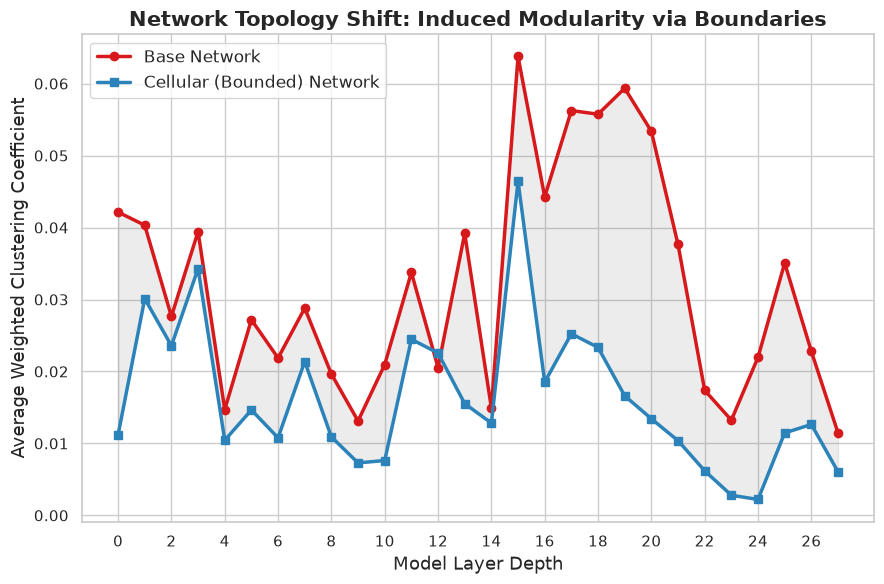

Global Average Clustering (Base): 0.0320
Global Average Clustering (Cell): 0.0162


In [17]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import os
from tqdm import tqdm

# ============================================================
# 1. LOAD DATA
# ============================================================
print("Loading attention tensors...")
data = np.load(os.path.join(RESULTS_DIR, "attention_run_0.npz"), allow_pickle=True)

attn_base = data["attn_base"]
attn_cell = data["attn_cell"]
tokens_base = data["tokens_base"]
tokens_cell = data["tokens_cell"]

# ============================================================
# 2. MASK BOUNDARIES and All Zero Heads
# ============================================================

# Create a mask to ignore '|' tokens
mask_cell = np.array([t != '|' for t in tokens_cell])

# Apply mask: crop both rows and columns to alphabetic tokens only
attn_cell_masked = attn_cell[:, :, mask_cell, :][:, :, :, mask_cell]
# Reverse Mask
#attn_cell_masked = attn_cell

num_layers, num_heads = attn_base.shape[:2]

# ============================================================
# 2. COMPUTE CLUSTERING COEFFICIENT (NETWORK TOPOLOGY)
# ============================================================
# We treat each attention matrix as a weighted, directed adjacency matrix.
# The clustering coefficient measures the degree to which nodes in a graph tend to cluster together.

# ============================================================
# 2. COMPUTE CLUSTERING COEFFICIENT (NETWORK TOPOLOGY)
# ============================================================

base_clustering_layers = np.zeros(num_layers)
cell_clustering_layers = np.zeros(num_layers)

# Define your threshold (e.g., 0.01 means ignore weights under 1%)
THRESHOLD = 0.1 

print(f"Computing network topologies with threshold {THRESHOLD}...")
for l in tqdm(range(num_layers), desc="Processing Layers"):
    base_head_cluster = []
    cell_head_cluster = []
    
    for h in range(num_heads):
        # --- Base Network ---
        m_base = attn_base[l, h].copy()
        # Apply Threshold: Zero out weak connections
        m_base[m_base < THRESHOLD] = 0.0
        
        # Create a directed graph from the thresholded matrix
        G_base = nx.from_numpy_array(m_base, create_using=nx.DiGraph)
        # Drop self-attention edges (the diagonal) before computing clustering:
        # nx's directed weighted clustering coefficient divides by a term built
        # from each node's self-loop weight, so a node whose only strong edge
        # is its own diagonal entry (very common post-threshold) hits 0/0 -> NaN.
        # Self-attention isn't meaningful for "clustering with other tokens" anyway.
        G_base.remove_edges_from(nx.selfloop_edges(G_base))
        base_vals = list(nx.clustering(G_base, weight='weight').values())
        c_base = np.nanmean(base_vals) if base_vals else 0.0
        base_head_cluster.append(c_base)
        
        # --- Cellular (Boundary) Network ---
        m_cell = attn_cell_masked[l, h].copy()
        # Apply Threshold: Zero out weak connections
        m_cell[m_cell < THRESHOLD] = 0.0
        
        G_cell = nx.from_numpy_array(m_cell, create_using=nx.DiGraph)
        G_cell.remove_edges_from(nx.selfloop_edges(G_cell))
        cell_vals = list(nx.clustering(G_cell, weight='weight').values())
        c_cell = np.nanmean(cell_vals) if cell_vals else 0.0
        cell_head_cluster.append(c_cell)
        
    base_clustering_layers[l] = np.nanmean(base_head_cluster)
    cell_clustering_layers[l] = np.nanmean(cell_head_cluster)


# ============================================================
# 3. VISUALIZATION
# ============================================================
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 6))

plt.plot(range(num_layers), base_clustering_layers, label="Base Network", 
         marker='o', markersize=6, linewidth=2.5, color='#d7191c')
plt.plot(range(num_layers), cell_clustering_layers, label="Cellular (Bounded) Network", 
         marker='s', markersize=6, linewidth=2.5, color='#2b83ba')

# Fill the gap to emphasize the difference
plt.fill_between(range(num_layers), base_clustering_layers, cell_clustering_layers, 
                 color='gray', alpha=0.15)

plt.xlabel("Model Layer Depth", fontsize=13)
plt.ylabel("Average Weighted Clustering Coefficient", fontsize=13)
plt.title("Network Topology Shift: Induced Modularity via Boundaries", fontsize=15, fontweight='bold')
plt.xticks(range(0, num_layers, 2))
plt.legend(fontsize=12, loc='upper left')

plot_filename = os.path.join(RESULTS_DIR, "topology_clustering_analysis.png")
plt.tight_layout()
plt.savefig(plot_filename, dpi=300)
print(f"\nSaved topology analysis plot to {plot_filename}")
plt.show()

# Print global averages
print(f"Global Average Clustering (Base): {np.nanmean(base_clustering_layers):.4f}")
print(f"Global Average Clustering (Cell): {np.nanmean(cell_clustering_layers):.4f}")

# Sample Presentation 

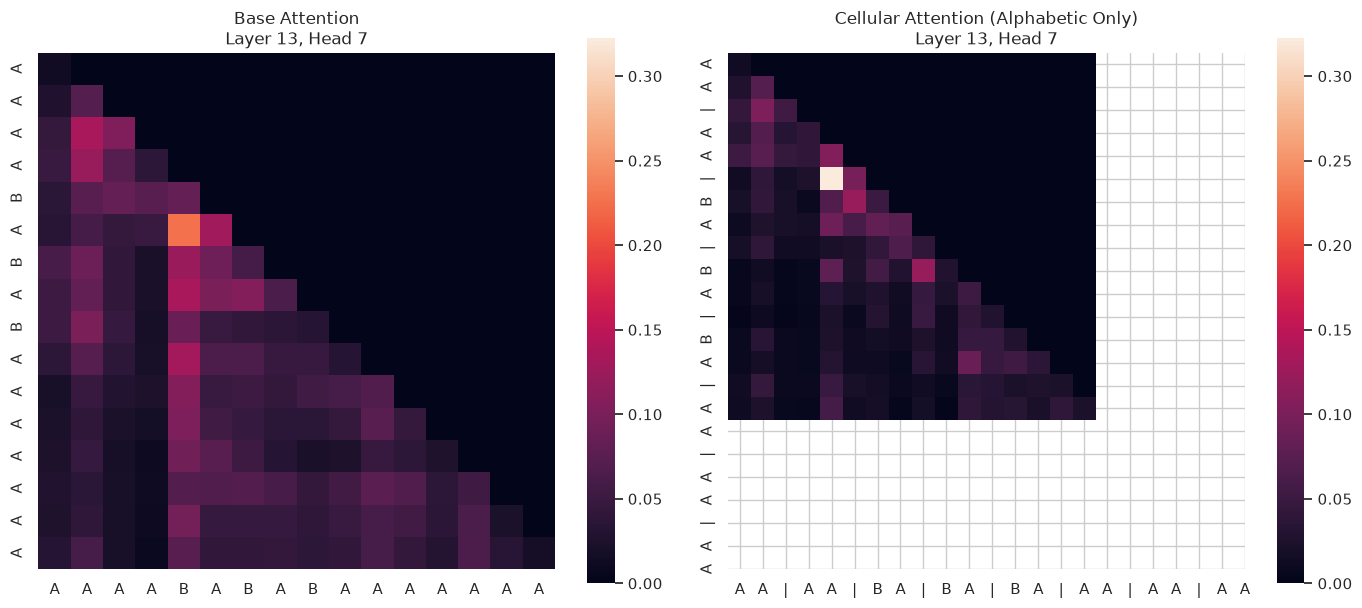

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# --- Load data ---
data = np.load(os.path.join(RESULTS_DIR, "attention_run_0.npz"), allow_pickle=True)

attn_base = data["attn_base"]
attn_cell = data["attn_cell"]
tokens_base = data["tokens_base"]
tokens_cell = data["tokens_cell"]

# --- Mask boundaries for cellular ---
mask_cell = np.array([t != '|' for t in tokens_cell])
attn_cell_masked = attn_cell[:, :, mask_cell, :][:, :, :, mask_cell].copy()

tokens_cell_masked = np.array(tokens_cell)[mask_cell]

# Reverse Mask
#attn_cell_masked = attn_cell
tokens_cell_masked = tokens_cell

# --- Layer and Head to visualize ---
layer_idx = 13
head_idx = 7

m_base = attn_base[layer_idx, head_idx]
m_cell = attn_cell_masked[layer_idx, head_idx]

tokens_base_list = tokens_base
tokens_cell_list = tokens_cell_masked

vmax_shared = max(np.max(m_base), np.max(m_cell))

# --- Plot ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Base
sns.heatmap(
    m_base,
    xticklabels=tokens_base_list,
    yticklabels=tokens_base_list,
    cmap="rocket",
    vmin=0, vmax=vmax_shared,
    ax=ax1
)
ax1.set_title(f"Base Attention\nLayer {layer_idx}, Head {head_idx}", fontsize=12)
ax1.set_aspect('equal')

# Cellular (alphabetic only)
sns.heatmap(
    m_cell,
    xticklabels=tokens_cell_list,
    yticklabels=tokens_cell_list,
    cmap="rocket",
    vmin=0, vmax=vmax_shared,
    ax=ax2
)
ax2.set_title(f"Cellular Attention (Alphabetic Only)\nLayer {layer_idx}, Head {head_idx}", fontsize=12)
ax2.set_aspect('equal')

plt.tight_layout()
plt.savefig("example.png",dpi=300)
plt.show()

# OFF-Attention Weght Prob Distrition 

Mean Base context mass: 0.2792288613918961
Mean Cellular context mass: 0.20370898291449638
Mean Δ: -0.07551987847739981


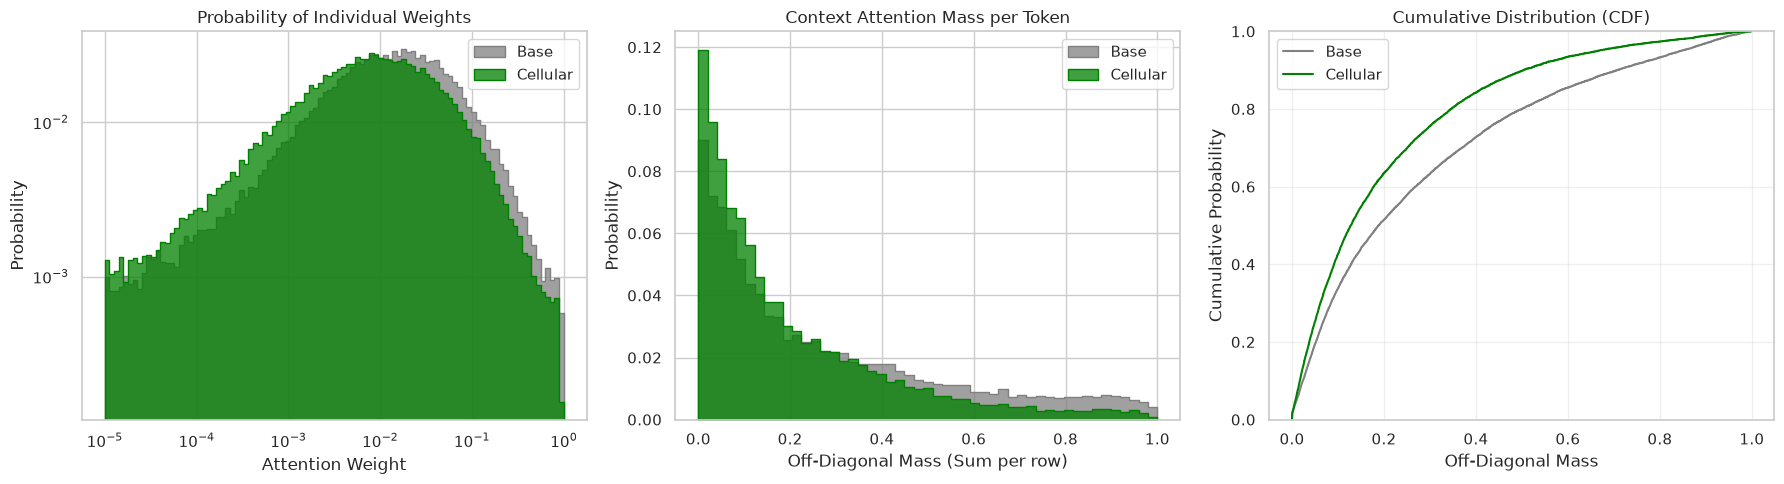

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# ============================================================
# LOAD DATA
# ============================================================

data = np.load(os.path.join(RESULTS_DIR, "attention_run_0.npz"), allow_pickle=True)

attn_base = data["attn_base"]
attn_cell = data["attn_cell"]
tokens_base = data["tokens_base"]
tokens_cell = data["tokens_cell"]

# ============================================================
# MASK CELLULAR BOUNDARY TOKENS
# ============================================================

mask_cell = np.array([t != '|' for t in tokens_cell])

attn_cell_masked = attn_cell[:, :, mask_cell, :][:, :, :, mask_cell].copy()
tokens_cell_masked = np.array(tokens_cell)[mask_cell]

#attn_cell_masked = attn_cell
tokens_cell_masked = tokens_cell

# ============================================================
# FUNCTIONS
# ============================================================

def offdiag_fraction(attn_tensor):
    """
    Mean off-diagonal mass per (layer, head)
    """
    L, H = attn_tensor.shape[:2]
    frac = np.zeros((L, H))

    for l in range(L):
        for h in range(H):
            m = attn_tensor[l, h]
            off = np.tril(m, k=-1).sum(axis=1)
            frac[l, h] = off[1:].mean()

    return frac


def offdiag_values(attn_tensor):
    """
    Collects all individual off-diagonal attention weights
    """
    L, H = attn_tensor.shape[:2]
    vals = []

    for l in range(L):
        for h in range(H):
            m = attn_tensor[l, h]
            N = m.shape[0]

            for i in range(N):
                off = np.delete(m[i, :], i)
                vals.extend(off)

    return np.array(vals)


def offdiag_mass_per_row(attn_tensor):
    """
    Total off-diagonal mass per token
    """
    L, H = attn_tensor.shape[:2]
    vals = []

    for l in range(L):
        for h in range(H):
            m = attn_tensor[l, h]
            off = np.tril(m, k=-1).sum(axis=1)
            vals.extend(off[1:])  # skip first token

    return np.array(vals)


# ============================================================
# COMPUTE METRICS
# ============================================================

ratio_base = offdiag_fraction(attn_base)
ratio_cell = offdiag_fraction(attn_cell_masked)

delta_ratio = ratio_cell - ratio_base

print("Mean Base context mass:", np.mean(ratio_base))
print("Mean Cellular context mass:", np.mean(ratio_cell))
print("Mean Δ:", np.mean(delta_ratio))


off_base_vals = offdiag_values(attn_base)
off_cell_vals = offdiag_values(attn_cell_masked)

off_base_mass = offdiag_mass_per_row(attn_base)
off_cell_mass = offdiag_mass_per_row(attn_cell_masked)

# PLOTS
# ============================================================

# We will create 3 plots: Weight Prob, Mass Prob, and Mass CDF
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ------------------------------------------------------------
# 1. Probability of Individual Weights (Log Scale)
# ------------------------------------------------------------
bins_log = np.logspace(-5, 0, 100)

for data, label, color in [(off_base_vals, "Base", "gray"), (off_cell_vals, "Cellular", "green")]:
    sns.histplot(
        data,
        bins=bins_log,
        stat="probability",  # Changed from density
        element="step",
        label=label,
        color=color,
        ax=axes[0]
    )

axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title("Probability of Individual Weights")
axes[0].set_xlabel("Attention Weight")
axes[0].set_ylabel("Probability")
axes[0].legend()

# ------------------------------------------------------------
# 2. Probability of Context Mass per Token
# ------------------------------------------------------------
bins_lin = np.linspace(0, 1, 50)

for data, label, color in [(off_base_mass, "Base", "gray"), (off_cell_mass, "Cellular", "green")]:
    sns.histplot(
        data,
        bins=bins_lin,
        stat="probability",  # Changed from density
        element="step",
        label=label,
        color=color,
        ax=axes[1]
    )

axes[1].set_title("Context Attention Mass per Token")
axes[1].set_xlabel("Off-Diagonal Mass (Sum per row)")
axes[1].set_ylabel("Probability")
axes[1].legend()

# ------------------------------------------------------------
# 3. Cumulative Distribution (CDF) of Mass
# ------------------------------------------------------------
# This shows: "What % of tokens have at least X amount of context mass?"
sns.ecdfplot(off_base_mass, label="Base", color="gray", ax=axes[2])
sns.ecdfplot(off_cell_mass, label="Cellular", color="green", ax=axes[2])

axes[2].set_title("Cumulative Distribution (CDF)")
axes[2].set_xlabel("Off-Diagonal Mass")
axes[2].set_ylabel("Cumulative Probability")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("off_diagonal_probability.png", dpi=300)
plt.show()

# Diagonal-Attention Weght Prob Distrition 

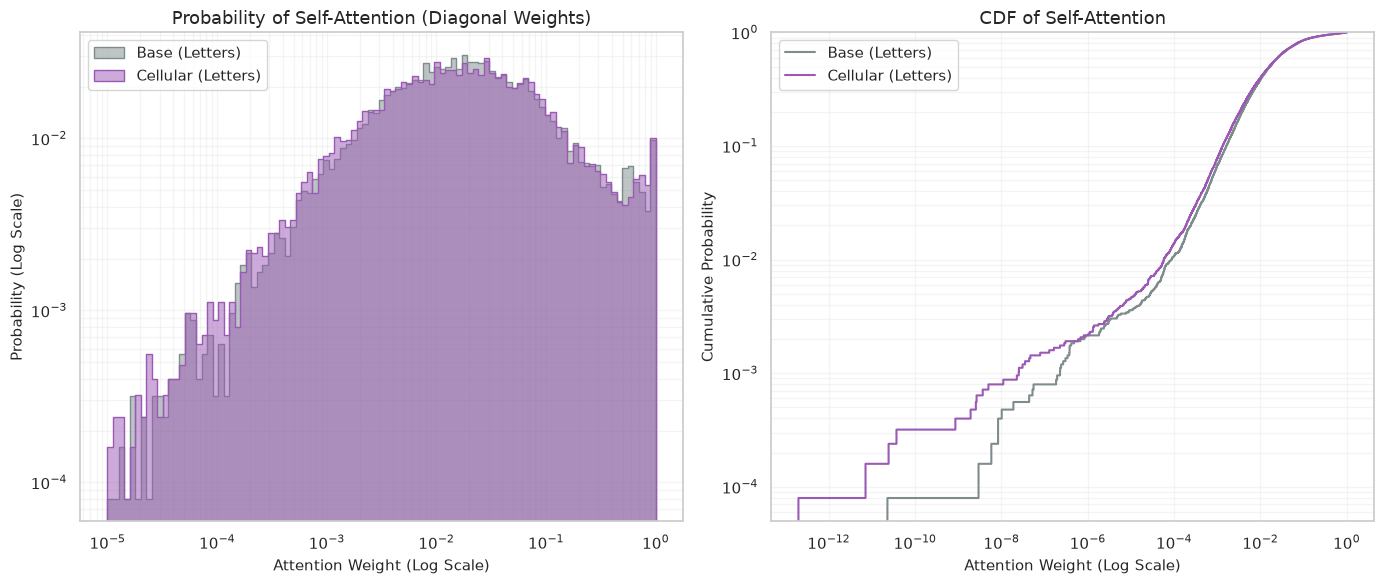

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os

# ============================================================
# LOAD DATA
# ============================================================
# Use the original 4D tensors (Layers, Heads, Seq, Seq)
data = np.load(os.path.join(RESULTS_DIR, "attention_run_0.npz"), allow_pickle=True)
attn_base = data["attn_base"]
attn_cell = data["attn_cell"]
tokens_base = np.array(data["tokens_base"])
tokens_cell = np.array(data["tokens_cell"])

# ============================================================
# DATA EXTRACTION (Diagonal Elements)
# ============================================================

def get_diagonal_elements(attn_tensor, tokens):
    """
    Extracts diagonal values for all layers/heads, excluding dividers.
    Supports 4D (L,H,N,N) tensors.
    """
    L, H, N, _ = attn_tensor.shape
    diag_vals = []
    
    # Identify non-divider indices
    alpha_indices = np.where(np.array(tokens) != '|')[0]

    for l in range(L):
        for h in range(H):
            m = attn_tensor[l, h]
            d = np.diag(m)  # Get the full diagonal
            # Filter out dividers
            alpha_diags = d[alpha_indices]
            diag_vals.extend(alpha_diags)
            
    return np.array(diag_vals)

# Compute values
# We use the raw 4D data to ensure we have the full distribution across all heads
diag_base = get_diagonal_elements(attn_base, tokens_base)
diag_cell = get_diagonal_elements(attn_cell, tokens_cell)

# ============================================================
# PLOTS (Probability with Log Scale)
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Define bins in log space for the X-axis
# We look at weights from 0.00001 up to 1.0
bins_log = np.logspace(-5, 0, 100)

# ------------------------------------------------------------
# 1. Probability Distribution (PDF) with Log Scale
# ------------------------------------------------------------
sns.histplot(
    diag_base,
    bins=bins_log,
    stat="probability",
    element="step",
    label="Base (Letters)",
    color="#7f8c8d", # Grey
    alpha=0.5,
    ax=axes[0]
)

sns.histplot(
    diag_cell,
    bins=bins_log,
    stat="probability",
    element="step",
    label="Cellular (Letters)",
    color="#9b59b6", # Purple
    alpha=0.5,
    ax=axes[0]
)

axes[0].set_xscale("log")
# We also log the Y-axis to see the differences in extremely low/high probability regions
axes[0].set_yscale("log") 

axes[0].set_title("Probability of Self-Attention (Diagonal Weights)", fontsize=13)
axes[0].set_xlabel("Attention Weight (Log Scale)", fontsize=11)
axes[0].set_ylabel("Probability (Log Scale)", fontsize=11)
axes[0].legend()
axes[0].grid(True, which="both", alpha=0.2)

# ------------------------------------------------------------
# 2. Cumulative Distribution (CDF) with Log Scale X-axis
# ------------------------------------------------------------
sns.ecdfplot(diag_base, label="Base (Letters)", color="#7f8c8d", ax=axes[1])
sns.ecdfplot(diag_cell, label="Cellular (Letters)", color="#9b59b6", ax=axes[1])

axes[1].set_xscale("log")
axes[1].set_yscale("log") 

axes[1].set_title("CDF of Self-Attention", fontsize=13)
axes[1].set_xlabel("Attention Weight (Log Scale)", fontsize=11)
axes[1].set_ylabel("Cumulative Probability", fontsize=11)
axes[1].legend()
axes[1].grid(True, which="both", alpha=0.2)

plt.tight_layout()
plt.show()

# Correlation Decay

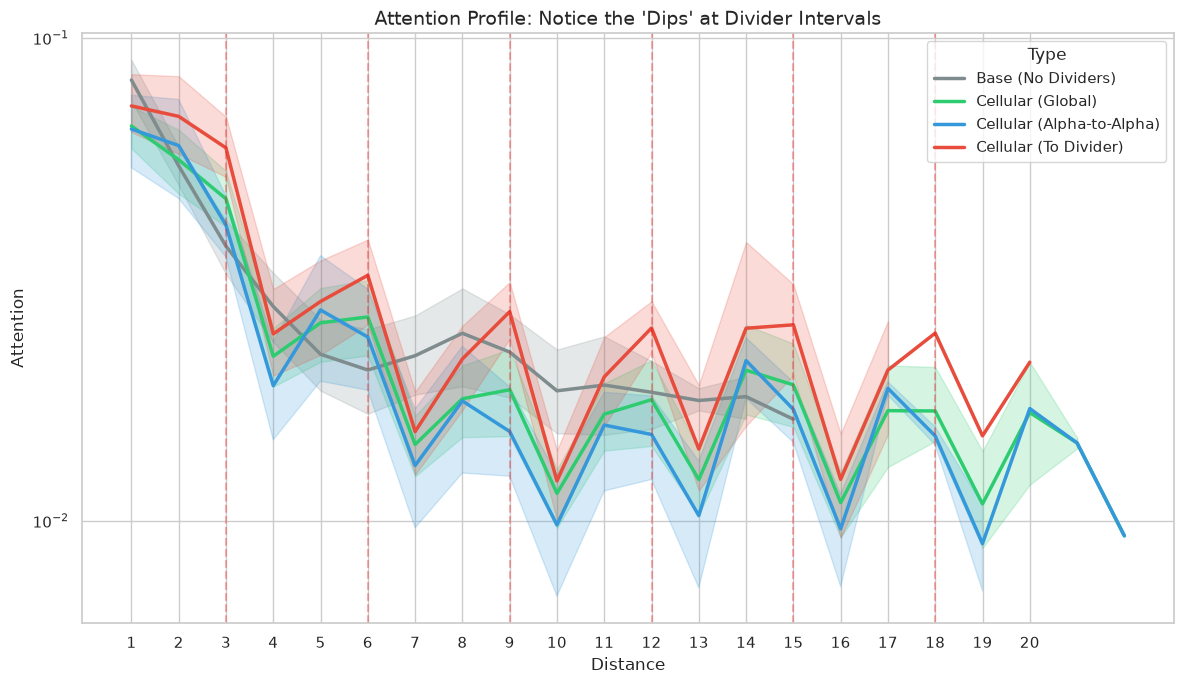

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os

# ============================================================
# LOAD DATA
# ============================================================
data = np.load(os.path.join(RESULTS_DIR, "attention_run_0.npz"), allow_pickle=True)

# Average across Layers (L) and Heads (H) to get (N, N) matrices
attn_base = data["attn_base"].mean(axis=(0, 1))
attn_cell = data["attn_cell"].mean(axis=(0, 1))

tokens_base = np.array(data["tokens_base"])
tokens_cell = np.array(data["tokens_cell"])

palette = {
    "Base (No Dividers)": "#7f8c8d",      # Grey (Baseline)
    "Cellular (Global)": "#2ecc71",       # Green (Full Cellular model)
    "Cellular (To Divider)": "#e74c3c",   # Red (Attention focused on '|')
    "Cellular (Alpha-to-Alpha)": "#3498db" # Blue (Letter-to-letter context)
}

# ============================================================
# DATA EXTRACTION
# ============================================================
results = []

# 1. PROCESS BASE MODEL (Pure Alphabet)
N_base = attn_base.shape[0]
for i in range(1, N_base):
    for j in range(i):
        results.append({
            "Distance": i - j,
            "Attention": attn_base[i, j],
            "Type": "Base (No Dividers)"
        })

# 2. PROCESS CELLULAR MODEL (Mixed)
N_cell = attn_cell.shape[0]
div_idx = np.where(tokens_cell == "|")[0]
alpha_idx = np.where(tokens_cell != "|")[0]

for i in range(1, N_cell):
    for j in range(i):
        dist = i - j
        val = attn_cell[i, j]
        
        # Cellular (All)
        results.append({"Distance": dist, "Attention": val, "Type": "Cellular (Global)"})
        
        # Cellular (To Divider)
        if j in div_idx:
            results.append({"Distance": dist, "Attention": val, "Type": "Cellular (To Divider)"})
            
        # Cellular (Alpha -> Alpha)
        if i in alpha_idx and j in alpha_idx:
            results.append({"Distance": dist, "Attention": val, "Type": "Cellular (Alpha-to-Alpha)"})

df = pd.DataFrame(results)

# ============================================================
# PLOT
# ============================================================
plt.figure(figsize=(12, 7))

# Plot the lines
sns.lineplot(data=df, x="Distance", y="Attention", hue="Type", palette=palette, linewidth=2.5)

# ADD VERTICAL LINES every 5 tokens (divider positions)
for d in range(3, 21, 3):
    plt.axvline(x=d, color='red', linestyle='--', alpha=0.3, label='Divider Gap' if d==5 else "")

plt.title("Attention Profile: Notice the 'Dips' at Divider Intervals", fontsize=14)
#plt.xlim(1, 20)
plt.yscale('log')
plt.xticks(range(1, 21))

# Add a note about the missing distances
plt.annotate('Alpha-to-Alpha dips\nbecause a Divider is at this distance', 
             xy=(5, 0), xytext=(6, 0.02),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=5))
plt.tight_layout()
plt.savefig('attention_distance_profile.png',dpi=300)
plt.show()

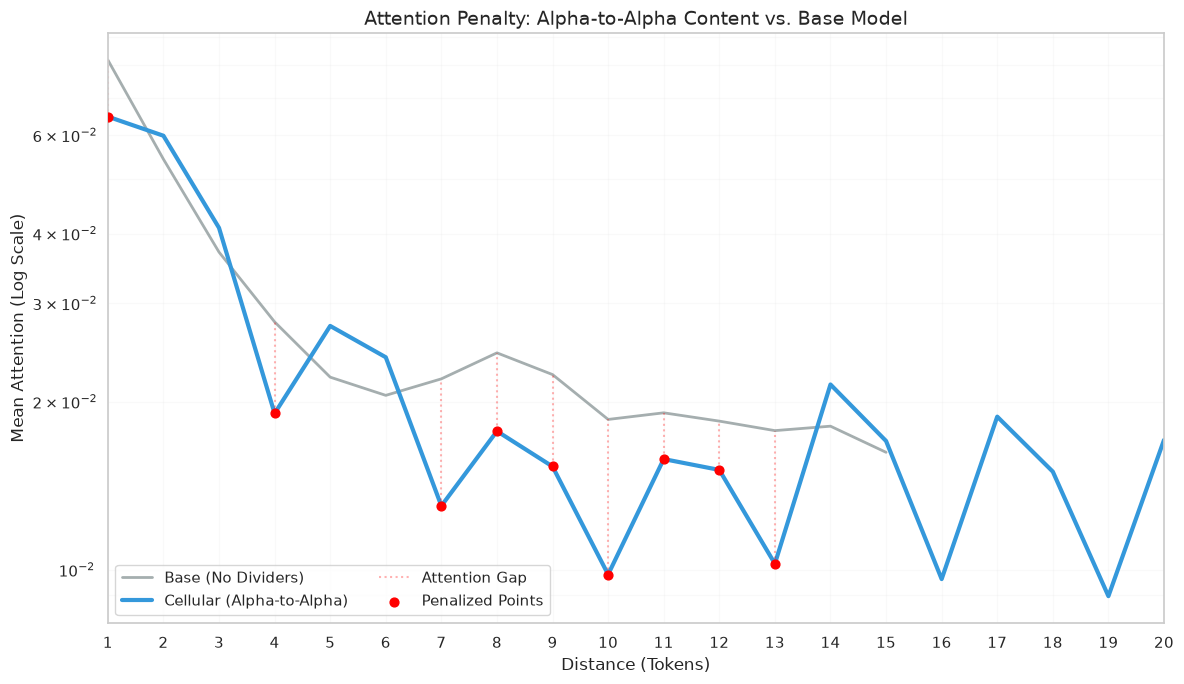

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os

# ============================================================
# LOAD DATA
# ============================================================
data = np.load(os.path.join(RESULTS_DIR, "attention_run_0.npz"), allow_pickle=True)

# Average across Layers and Heads
attn_base = data["attn_base"].mean(axis=(0, 1))
attn_cell = data["attn_cell"].mean(axis=(0, 1))

tokens_base = np.array(data["tokens_base"])
tokens_cell = np.array(data["tokens_cell"])

# ============================================================
# DATA EXTRACTION
# ============================================================
results = []

# 1. Base Model processing
N_base = attn_base.shape[0]
for i in range(1, N_base):
    for j in range(i):
        results.append({
            "Distance": i - j,
            "Attention": attn_base[i, j],
            "Type": "Base (No Dividers)"
        })

# 2. Cellular Alpha-to-Alpha processing
N_cell = attn_cell.shape[0]
alpha_idx = np.where(tokens_cell != "|")[0]

for i in range(1, N_cell):
    for j in range(i):
        if i in alpha_idx and j in alpha_idx:
            results.append({
                "Distance": i - j,
                "Attention": attn_cell[i, j],
                "Type": "Cellular (Alpha-to-Alpha)"
            })

df = pd.DataFrame(results)
summary = df.groupby(['Distance', 'Type'])['Attention'].mean().unstack()

# ============================================================
# PLOT
# ============================================================
plt.figure(figsize=(12, 7))

# Plot lines
plt.plot(summary.index, summary["Base (No Dividers)"], 
         label="Base (No Dividers)", color="#7f8c8d", linewidth=2, alpha=0.7)
plt.plot(summary.index, summary["Cellular (Alpha-to-Alpha)"], 
         label="Cellular (Alpha-to-Alpha)", color="#3498db", linewidth=3)

# Find where Cellular < Base
penalty_mask = summary["Cellular (Alpha-to-Alpha)"] < summary["Base (No Dividers)"]
penalty_dists = summary.index[penalty_mask]
penalty_vals = summary["Cellular (Alpha-to-Alpha)"][penalty_mask]

# 1. Highlight the gap with vertical error bars (stems)
plt.vlines(penalty_dists, penalty_vals, summary["Base (No Dividers)"][penalty_mask], 
           color='red', alpha=0.3, linestyles=':', label='Attention Gap')

# 2. Add singular red dots on points where attention is lower
plt.scatter(penalty_dists, penalty_vals, color='red', s=40, zorder=5, label='Penalized Points')

plt.yscale('log')
plt.title("Attention Penalty: Alpha-to-Alpha Content vs. Base Model", fontsize=14)
plt.xlabel("Distance (Tokens)", fontsize=12)
plt.ylabel("Mean Attention (Log Scale)", fontsize=12)
plt.xlim(1, 20)
plt.xticks(range(1, 21))
plt.grid(True, which="both", ls="-", alpha=0.1)
plt.legend(frameon=True, loc='lower left', ncol=2)

plt.tight_layout()
plt.show()

# Model-Scale Comparison

Found results for 2 model scale(s): ['Qwen2.5-14B-Instruct', 'Qwen2.5-7B-Instruct']

--- MODEL-SCALE COMPARISON ---
               Model  Params_B  SAR_Base  SAR_Cellular_Bounds  Alpha_Base  Alpha_Cellular  Alpha_Reduction_%  Mean_Boundary_Attn  Mean_Delta_Entropy  Mean_Delta_Clustering
 Qwen2.5-7B-Instruct       7.0    0.0429               0.0639      1.3053          1.1958             8.3879              0.1048              0.1216                 0.0007
Qwen2.5-14B-Instruct      14.0       NaN                  NaN         NaN             NaN                NaN                 NaN                 NaN                    NaN



Saved plot to results/model_scale_comparison.png


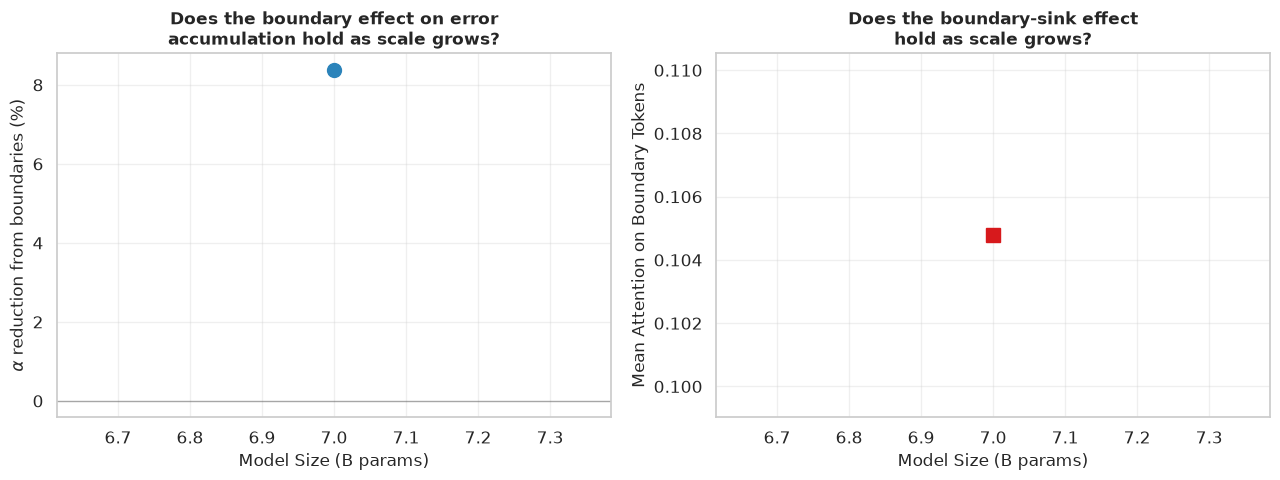

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re

# ============================================================
# MODEL-SCALE COMPARISON
# ============================================================
# Change MODEL_ID in the MODEL SELECTION cell near the top of this notebook
# and re-run top to bottom to populate results for another scale (e.g.
# Qwen2.5-14B-Instruct). This cell auto-discovers every results/<MODEL_TAG>/
# directory that has been run so far and compares them side by side --
# nothing to configure here, just re-run this cell after each new scale.

available_tags = sorted(
    d for d in os.listdir("results") if os.path.isdir(os.path.join("results", d))
) if os.path.isdir("results") else []

print(f"Found results for {len(available_tags)} model scale(s): {available_tags}")
if len(available_tags) < 2:
    print("\nOnly one model scale has been run so far -- nothing to compare yet.")
    print("Change MODEL_ID in the MODEL SELECTION cell near the top, re-run the")
    print("notebook top to bottom for that scale, then re-run this cell.")

def parse_param_count(tag):
    # e.g. "Qwen2.5-7B-Instruct" -> 7.0, "Qwen2.5-14B-Instruct" -> 14.0
    m = re.search(r'(\d+(?:\.\d+)?)B', tag)
    return float(m.group(1)) if m else float('nan')

rows = []
for tag in available_tags:
    d = os.path.join("results", tag)
    entry = {"Model": tag, "Params_B": parse_param_count(tag)}

    thermo_path = os.path.join(d, "thermodynamics_grid.csv")
    if os.path.exists(thermo_path):
        df = pd.read_csv(thermo_path)
        for method, sub in df.groupby("Method"):
            entry[f"SAR_{method}"] = sub["SAR"].mean()

    sk_path = os.path.join(d, "thermodynamics_sk_fit.csv")
    if os.path.exists(sk_path):
        sk = pd.read_csv(sk_path)
        base_alpha = sk[sk["Method"] == "Base"]["Alpha"].mean()
        cell_alpha = sk[sk["Method"] == "Cellular_Bounds"]["Alpha"].mean()
        entry["Alpha_Base"] = base_alpha
        entry["Alpha_Cellular"] = cell_alpha
        entry["Alpha_Reduction_%"] = 100 * (base_alpha - cell_alpha) / base_alpha if base_alpha else float("nan")

    attn_path = os.path.join(d, "attention_metrics.csv")
    if os.path.exists(attn_path):
        attn = pd.read_csv(attn_path)
        entry["Mean_Boundary_Attn"] = attn["Cell_Boundary_Attn"].mean()
        entry["Mean_Delta_Entropy"] = attn["Delta_Entropy"].mean()
        if "Delta_Clustering" in attn.columns:
            entry["Mean_Delta_Clustering"] = attn["Delta_Clustering"].mean()

    rows.append(entry)

comparison_df = pd.DataFrame(rows).sort_values("Params_B")
print("\n--- MODEL-SCALE COMPARISON ---")
print(comparison_df.round(4).to_string(index=False))

if len(comparison_df) >= 2:
    comparison_df.to_csv(os.path.join("results", "model_scale_comparison.csv"), index=False)

    sns.set_theme(style="whitegrid", font_scale=1.1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    if "Alpha_Reduction_%" in comparison_df.columns:
        axes[0].plot(comparison_df["Params_B"], comparison_df["Alpha_Reduction_%"],
                     marker='o', markersize=10, linewidth=2, color='#2b83ba')
        axes[0].axhline(0.0, color='black', linestyle='-', alpha=0.3, linewidth=1)
        axes[0].set_xlabel("Model Size (B params)", fontsize=12)
        axes[0].set_ylabel(r"$\alpha$ reduction from boundaries (%)", fontsize=12)
        axes[0].set_title("Does the boundary effect on error\naccumulation hold as scale grows?",
                           fontsize=12, fontweight='bold')
        axes[0].grid(True, alpha=0.3)

    if "Mean_Boundary_Attn" in comparison_df.columns:
        axes[1].plot(comparison_df["Params_B"], comparison_df["Mean_Boundary_Attn"],
                     marker='s', markersize=10, linewidth=2, color='#d7191c')
        axes[1].set_xlabel("Model Size (B params)", fontsize=12)
        axes[1].set_ylabel("Mean Attention on Boundary Tokens", fontsize=12)
        axes[1].set_title("Does the boundary-sink effect\nhold as scale grows?",
                           fontsize=12, fontweight='bold')
        axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plot_path = os.path.join("results", "model_scale_comparison.png")
    plt.savefig(plot_path, dpi=300, bbox_inches='tight')
    print(f"\nSaved plot to {plot_path}")
    plt.show()